# Pile-up rejection sui light detector di CROSS (run m205)
## Un punto, dalla misura al BI: ampiezze → template → addestramento → Monte Carlo

Il notebook ripercorre **tutta la catena** dell'analisi del pile-up su **un solo punto** (un canale e un working
point), in scala ridotta, con le correzioni introdotte dopo la tesi:

| | campagna | qui |
|---|---|---|
| punti | 5 canali × 15 WP | 1 (`CH`, `WP` nella cella di configurazione) |
| passi di addestramento | 500 | `N_STEPS` (default 40) |
| Monte Carlo | 50 seed × (50 000 singoli + 50 000 pile-up) | 1 seed × (50 000 + 50 000) |

Le funzioni sono **quelle dei programmi della campagna**, non copie: il loro sorgente è stampato nel notebook
(`show(...)`), quindi quello che si legge è esattamente quello che gira.

### Cosa cambia rispetto alla tesi
1. **Ritardo massimo del pile-up = rise time del punto** (sez. 3): $\Delta t_{\max}$ è il rise time 10–90% di quel
   canale e WP, invece di 0.8 ms per tutti. La griglia dei ritardi dell'addestramento ha sempre 100 punti.
2. **Generazione degli eventi** (sez. 6), come nel paper: fluttuazione del numero di fotoni (con il light yield di
   ogni canale misurato da Denys, fotoni a 670 nm; sez. 1.3), energia somma in [3019, 3049] keV, shift sub-campione
   dell'inizio dell'impulso.
3. **Template di addestramento** (sez. 4): media di 10 000 impulsi LED simulati, con la baseline presa **prima
   dell'impulso** e gli impulsi **allineati sul massimo**, come si fa con gli impulsi veri.
4. **Baseline nel Monte Carlo** (sez. 6): ogni evento si corregge con la media del pretrigger. Nella tesi la funzione
   che calcola il discriminante toglieva la media di **tutta** la finestra, impulso compreso.

Le funzioni della tesi non sono cambiate: le novità stanno in nuove varianti o in opzioni spente per default, e con
quelle spente il Monte Carlo riproduce bit per bit i numeri della tesi.

**Come eseguirlo**: kernel `/opt/homebrew/bin/python3.13` (quello del progetto, con torch e uproot), circa 15 minuti
su un Mac da 8 GB. Il Mac deve restare sveglio (alimentatore collegato, oppure `caffeinate -i`).

In [1]:
import os, sys, csv, time, inspect
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")   # torch + scipy/uproot sul Mac
os.environ.setdefault("OMP_NUM_THREADS", "1")
BASE = os.path.abspath("")                               # il notebook sta nella radice del progetto
sys.path.insert(0, BASE)

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline

import src.analysis as an                    # filtro ottimo, modello analitico, addestramento, discriminante Y
import src.simulation as sim                 # generatore degli eventi (originale e v2)
import utility.functions as fn               # K del BI, rise time, fotoni
import utility.double_beta_spectrum as dbs   # spettro 2nbb, distribuzione di r, energia somma nella ROI
import build_simAP_injected_m205 as bs       # template di addestramento (AP simulato)
import analyse_BI_m205 as ab                 # addestramento del filtro ottimo (il programma della campagna)
import simulate_BI_error_m205 as mc          # Monte Carlo del BI (il programma della campagna)

from IPython.display import display, Markdown


def _code(where, src):
    # blocco di codice Markdown (```python): VS Code e Jupyter lo colorano con il tema dell'editor
    display({"text/markdown": f"`{where}`\n\n```python\n{src}```", "text/plain": f"# {where}\n\n{src}"}, raw=True)


def show(f):
    # il sorgente di una funzione del progetto, con file e riga
    _code(f"{os.path.relpath(inspect.getsourcefile(f), BASE)}:{inspect.getsourcelines(f)[1]}", inspect.getsource(f))


def show_block(module, first, last):
    # le righe di un modulo da quella che contiene `first` a quella che contiene `last` (costanti, dizionari)
    lines = inspect.getsource(module).splitlines(keepends=True)
    i = next(k for k, l in enumerate(lines) if first in l)
    j = next(k for k, l in enumerate(lines) if k >= i and last in l)
    _code(f"{os.path.relpath(inspect.getsourcefile(module), BASE)}:{i + 1}", "".join(lines[i:j + 1]))


plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
CHANNELS = [31, 34, 71, 83, 91]

In [2]:
CH, WP  = 31, 7          # canale e working point (WP dispari, 1..29)
N_STEPS = 40             # passi di addestramento (campagna: 500)
NSIM    = 50_000         # eventi per popolazione nel Monte Carlo (campagna: lo stesso, per 50 seed)
SEED    = 1234           # seed del Monte Carlo (il primo dei 50 della campagna)
FS      = 10_000         # frequenza di campionamento [Hz]
VBIAS   = float(ab.wp_to_vbias(WP))

assert ab.T_MAX == "rise", "analyse_BI_m205.T_MAX deve essere 'rise'"
print(f"ch{CH} WP{WP}: V_bias = {VBIAS} V")

ch31 WP7: V_bias = 1.8 V


## 1. Le ampiezze del segnale

L'ampiezza del segnale a $Q_{\beta\beta}$ è il numero che più conta per il pile-up: fissa il rapporto segnale/rumore
con cui si distinguono i due impulsi. Si costruisce in due passi (1.1 e 1.2); la 1.3 descrive la sua fluttuazione
da evento a evento, dovuta al numero di fotoni.

### 1.1 L'ampiezza dei LED
I punti della load curve (15 WP per canale) sono presi con il **LED**: per ogni WP l'ampiezza è la mediana
dell'ampiezza del filtro ottimo di Octopus sugli impulsi LED buoni (`optimumfilter__wp<wp>.amplitude`, `good == 1`).

In [3]:
show(bs.led_amp_of)
A_LED = bs.led_amp_of(CH, WP)                 # [V]
print(f"A_LED(ch{CH}, WP{WP}) = {A_LED * 1e3:.1f} mV")

`build_simAP_injected_m205.py:300`

```python
def led_amp_of(channel, wp):
    """Ampiezza LED del WP [V], versione v2: mediana dell'ampiezza del FILTRO OTTIMO di Octopus
    (optimumfilter__wp<wp>, eventi con good == 1). E' la stessa grandezza da cui
    risetime_and_amplitude_.py ricava l'ampiezza di ROI di amplitudes_m205.csv; led_amp usa
    invece maxminusbaseline. Le due mediane differiscono meno dello 0.1%."""
    with uproot.open(root_file(channel)) as f:
        t = f[f"optimumfilter__wp{wp}"]
        a, good = t["amplitude"].array(library="np"), t["good"].array(library="np")
    return float(np.median(a[good == 1]))
```

A_LED(ch31, WP7) = 743.0 mV


### 1.2 L'ampiezza nella ROI: calibrazione con la riga del $^{208}$Tl
Il LED serve da **righello**: la sua ampiezza si misura a ogni WP, ma i suoi fotoni non sono quelli di scintillazione.
Nei rivelatori in Si il guadagno NTL sugli impulsi LED è circa **il doppio** di quello sulla luce del LMO (CROSS
status, 16/04/2026, p. 11). Per questo il rapporto fra luce vera e LED si misura direttamente nella calibrazione con
sorgente di torio (run m204), una volta per canale:

$$A_{\rm ROI}(\mathrm{m205},\,\mathrm{WP}) \;=\; A_{\rm LED}(\mathrm{m205},\,\mathrm{WP}) \times
\underbrace{\frac{A_{2615}(\mathrm{m204})\cdot 3034/2615}{A_{\rm LED}(\mathrm{m204})}}_{k_{\rm ch}}$$

con $A_{2615}$ l'ampiezza della luce degli eventi a 2615 keV nel LMO vicino, vista dal light detector (filtro ottimo,
Roberto; Excel `2026 CROSS pile-up Analysis Alberto.xlsx`, colonne H e F, righe 2–9 e 22–29). Il guadagno vero sugli
eventi di scintillazione è quindi già dentro $k_{\rm ch}$. Il rapporto si suppone uguale a tutti i WP, cioè che la
tensione NTL sia la stessa in m204 e m205: sì, dalla run 199 tutti e cinque i canali sono a 120 V (logbook della RUN14).

In [4]:
# m204, filtro ottimo [mV]: luce a 2615 keV (Excel, colonna H) e impulsi LED (colonna F)
M204 = {31: (6.6, 1600), 34: (7.2, 1030), 71: (12.2, 1370), 83: (9.1, 760), 91: (4.4, 2200)}
k_ch = {ch: a2615 * 3034 / 2615 / led for ch, (a2615, led) in M204.items()}

amps = ab.load_signal_amplitudes(os.path.join(BASE, "amplitudes_m205.csv"))   # [V], scritto da risetime_and_amplitude_.py
A_ROI = amps[(CH, round(VBIAS, 3))]
print(" ch   A_2615(m204)  A_3034(m204)  A_LED(m204)   k_ch = 1/...")
for ch, (a2615, led) in M204.items():
    print(f"{ch:3d}   {a2615:8.1f} mV  {a2615 * 3034 / 2615:9.2f} mV  {led:7.0f} mV   {k_ch[ch]:.5f} = 1/{1 / k_ch[ch]:.1f}")
assert abs(A_LED * k_ch[CH] / A_ROI - 1) < 1e-3, "A_LED * k_ch non e' l'ampiezza del CSV"
print(f"\nch{CH} WP{WP}:  A_ROI = A_LED * k_ch = {A_LED * 1e3:.1f} mV * {k_ch[CH]:.5f} = {A_ROI * 1e3:.3f} mV  (= amplitudes_m205.csv)")

 ch   A_2615(m204)  A_3034(m204)  A_LED(m204)   k_ch = 1/...
 31        6.6 mV       7.66 mV     1600 mV   0.00479 = 1/208.9
 34        7.2 mV       8.35 mV     1030 mV   0.00811 = 1/123.3
 71       12.2 mV      14.15 mV     1370 mV   0.01033 = 1/96.8
 83        9.1 mV      10.56 mV      760 mV   0.01389 = 1/72.0
 91        4.4 mV       5.11 mV     2200 mV   0.00232 = 1/430.9

ch31 WP7:  A_ROI = A_LED * k_ch = 743.0 mV * 0.00479 = 3.556 mV  (= amplitudes_m205.csv)


### 1.3 La fluttuazione del numero di fotoni
Il numero di fotoni di scintillazione che il light detector assorbe è poissoniano, quindi l'ampiezza di ogni evento
fluttua con $\sigma_A/A = 1/\sqrt{N_\gamma}$. Nel Monte Carlo, come nel codice del paper, la fluttuazione è una
gaussiana di questa larghezza (`detector_sigma`, sez. 6). Il numero medio di fotoni a energia $E$ è

$$N_\gamma = \frac{\mathrm{LY}_{\rm ch}\cdot E}{E_\gamma},$$

- $\mathrm{LY}_{\rm ch}$: il light yield di ogni canale **prima dell'NTL**, verso il LMO vicino, misurato da Denys
  (run m92, NTL spento; foglio "Denys Comparison" di `ResultsCaraterization.xlsx`, CROSS status 16/04/2026 p. 7).
  Il guadagno NTL non entra: amplifica il segnale di ogni fotone, non il loro numero;
- $E_\gamma$ = 1.85 eV, un fotone a 670 nm (il codice del paper usava 2.30 eV).

In [5]:
show_block(fn, "PHOTON_EV  =", "0.09, 0.05, 0.05, 0.08, 0.08")
show(fn.n_photons)
LY_ERR = {31: 0.09, 34: 0.05, 71: 0.05, 83: 0.08, 91: 0.08}    # errori del foglio "Denys Comparison"
print(" ch    LY [keV/MeV]    N_gamma a Q_bb    sigma_A/A")
for ch in CHANNELS:
    n_ch = fn.n_photons(ch)
    print(f"{ch:3d}    {fn.LY_KEV_MEV[ch]:.2f} +- {LY_ERR[ch]:.2f}    {n_ch:9.0f}        {1 / np.sqrt(n_ch):.2%}")

N_GAMMA = fn.n_photons(CH)                                      # fotoni assorbiti a Q_bb da questo canale
fit = mc.template_pulse(CH, WP, "fit")                          # fit 7 poli x Bessel, picco = 1 (sez. 2)
nps = mc.load_noise(CH, WP)                                     # NPS pulita (sez. 2)
S_fit, w, H_fit = an.compute_H(fit, nps, np.hanning, sampling_rate=FS)   # S = FFT(fit * Hann), H = S*/NPS
sigma_OF = float(an.compute_sigma_OF(S_fit, nps))
print(f"\nch{CH} WP{WP}:  A_ROI = {A_ROI * 1e3:.3f} mV,  sigma_OF = {sigma_OF * 1e3:.4f} mV  ->  SNR_OF = {A_ROI / sigma_OF:.1f}")
print(f"fotoni: N_gamma = {N_GAMMA:.0f}  ->  sigma_A/A = {1 / np.sqrt(N_GAMMA):.2%},  da confrontare con il rumore 1/SNR_OF = {sigma_OF / A_ROI:.2%}")

`utility/functions.py:57`

```python
PHOTON_EV  = 1239.84 / 670  # energia di un fotone di scintillazione [eV]: 670 nm -> 1.85 eV (relatore).
                             # Il codice del paper usava 2.30 eV, Armatol 2026 (sez. 5.3) 2.1 eV.
LY_KEV_MEV = {31: 0.17, 34: 0.18, 71: 0.17, 83: 0.20, 91: 0.22}   # light yield prima dell'NTL,
                             # LMO vicino, misurato da Denys (m92; foglio "Denys Comparison" di
                             # ResultsCaraterization.xlsx; CROSS status 16/04/2026 p.7). Errori:
                             # 0.09, 0.05, 0.05, 0.08, 0.08.
```

`utility/functions.py:112`

```python
def n_photons(channel, energy_mev=Q_BB_MEV, cupid=False):
    """Fotoni di scintillazione assorbiti dal light detector per un evento di energy_mev:
        N = LY [keV/MeV] * E [MeV] * 1000 [eV/keV] / PHOTON_EV [eV],
    con LY del canale, o LY_CUPID se cupid. Statistica di Poisson -> sigma_A / A = 1 / sqrt(N)."""
    return (LY_CUPID if cupid else LY_KEV_MEV[channel]) * energy_mev * 1e3 / PHOTON_EV
```

 ch    LY [keV/MeV]    N_gamma a Q_bb    sigma_A/A
 31    0.17 +- 0.09          279        5.99%
 34    0.18 +- 0.05          295        5.82%
 71    0.17 +- 0.05          279        5.99%
 83    0.20 +- 0.08          328        5.52%
 91    0.22 +- 0.08          361        5.27%

ch31 WP7:  A_ROI = 3.556 mV,  sigma_OF = 0.1781 mV  ->  SNR_OF = 20.0
fotoni: N_gamma = 279  ->  sigma_A/A = 5.99%,  da confrontare con il rumore 1/SNR_OF = 5.01%


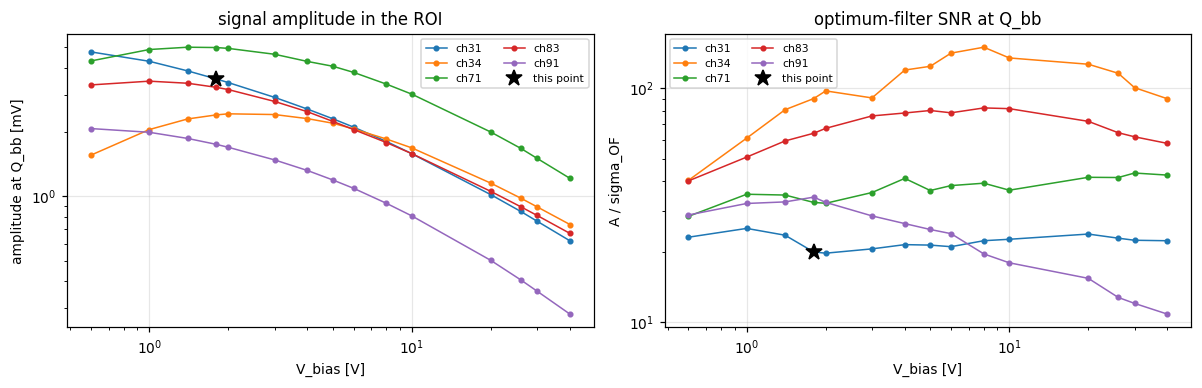

In [6]:
# ampiezza nella ROI e SNR del filtro ottimo su tutti i punti
pts = []
for (ch, vb), a in sorted(amps.items()):
    wp = 2 * int(np.flatnonzero(np.isclose(ab.VBIAS_LIST, vb))[0]) + 1 if ch in CHANNELS else None
    if wp is None or not os.path.exists(os.path.join(BASE, "residual_scan_bessel", "fits_octopus", f"bestfit_ch{ch}_wp{wp}.npy")):
        continue
    S_k, _, _ = an.compute_H(mc.template_pulse(ch, wp, "fit"), mc.load_noise(ch, wp), np.hanning, sampling_rate=FS)
    pts.append((ch, vb, a, a / float(an.compute_sigma_OF(S_k, mc.load_noise(ch, wp)))))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for ch in CHANNELS:
    vb, a, snr = np.array([p[1:] for p in pts if p[0] == ch]).T
    ax[0].plot(vb, a * 1e3, "o-", ms=3, lw=1, label=f"ch{ch}")
    ax[1].plot(vb, snr, "o-", ms=3, lw=1, label=f"ch{ch}")
ax[0].plot(VBIAS, A_ROI * 1e3, "k*", ms=11, label="this point")
ax[1].plot(VBIAS, A_ROI / sigma_OF, "k*", ms=11, label="this point")
for a_ in ax:
    a_.set(xscale="log", xlabel="V_bias [V]"); a_.legend(fontsize=7, ncol=2)
ax[0].set(yscale="log", ylabel="amplitude at Q_bb [mV]", title="signal amplitude in the ROI")
ax[1].set(yscale="log", ylabel="A / sigma_OF", title="optimum-filter SNR at Q_bb")
plt.tight_layout()

## 2. Template e rumore

- **AP di Octopus**: l'average pulse misurato, mediana dei 36–39 impulsi LED del WP, normalizzati al massimo.
  È rumoroso: su questo template l'addestramento "allucina" (cap. 4.2 della tesi).
- **fit**: 7 poli × filtro di Bessel del 6° ordine a 2.5 kHz (`scan_residuals_bessel_m205.py`). È il template liscio da
  cui il Monte Carlo **genera** gli eventi.
- **NPS pulita** (`build_NPS_clean_m205.py`): media dei periodogrammi delle finestre di rumore, nella convenzione
  $E|\mathrm{FFT}|^2$ in cui $\sigma_{OF} = \left(\sum_k |S_k|^2/N_k\right)^{-1/2}$.

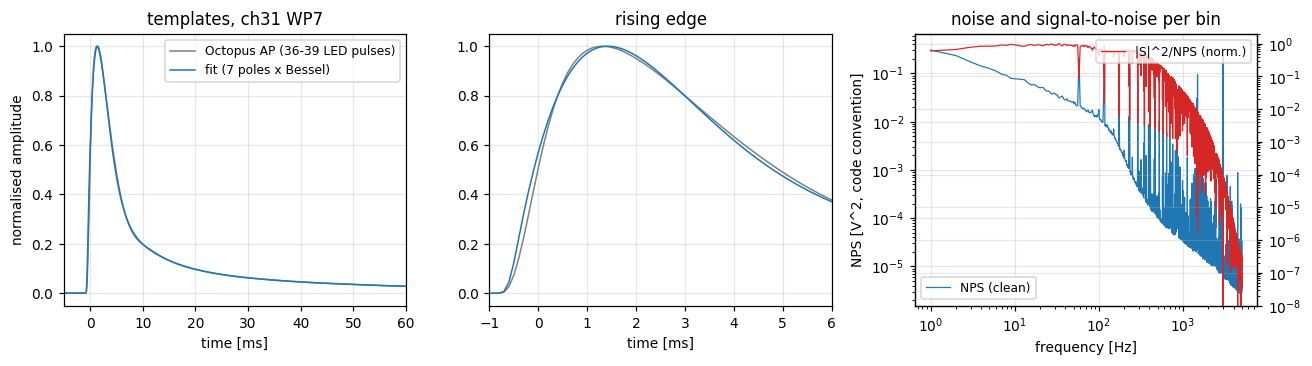

In [7]:
ap_oct = mc.template_pulse(CH, WP, "root")                 # AP di Octopus (dal file ROOT), picco = 1
t_ms = (np.arange(len(fit)) - len(fit) // 2) / FS * 1e3    # tempo dal centro della finestra
f = np.fft.rfftfreq(len(fit), 1 / FS)
half = len(f)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for v, lab, c in ((ap_oct, "Octopus AP (36-39 LED pulses)", "0.5"), (fit, "fit (7 poles x Bessel)", "C0")):
    ax[0].plot(t_ms, v, color=c, lw=1, label=lab)
    ax[1].plot(t_ms, v, color=c, lw=1)
ax[0].set(xlim=(-5, 60), xlabel="time [ms]", ylabel="normalised amplitude", title=f"templates, ch{CH} WP{WP}")
ax[1].set(xlim=(-1, 6), ylim=(-0.05, 1.05), xlabel="time [ms]", title="rising edge")
ax[0].legend(fontsize=8)
ax[2].loglog(f[1:], nps[1:half], lw=0.8, label="NPS (clean)")
ax2 = ax[2].twinx()
weight = np.abs(S_fit[:half]) ** 2 / nps[:half]
ax2.loglog(f[1:], weight[1:] / weight[1:].max(), color="C3", lw=0.8, label="|S|^2/NPS (norm.)")
ax2.set_ylim(1e-8, 2)
ax[2].set(xlabel="frequency [Hz]", ylabel="NPS [V^2, code convention]", title="noise and signal-to-noise per bin")
ax[2].legend(loc="lower left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout()

## 3. Il ritardo massimo del pile-up: il rise time del punto

Il BI conta i pile-up con ritardo $\Delta t \in [0, \Delta t_{\max}]$, quelli **non risolti**, e assume che i più
distanti si riconoscano sempre. Il paper definisce non risolto un pile-up con $\Delta t$ minore del rise time
(10–90%); con impulsi che salgono in 0.5–0.8 ms usava 0.8 ms per tutti. I nostri impulsi salgono in 0.3–2.4 ms, e
il rise time cambia molto con il WP: con 0.8 ms per tutti, i punti lenti perdono dal conto pile-up che non sono
risolti, quelli veloci contano pile-up già separati.

Per questo $\Delta t_{\max}$ è **il rise time di quel canale e WP** (`fn.dt_max_for`, colonna `risetime_ms` di
`amplitudes_m205.csv`). Quando i due impulsi sono più distanti del tempo di salita il secondo inizia dopo il massimo
del primo, e si riconosce con metodi più semplici (per esempio la forma della discesa). Il discriminante $Y$ invece lì
peggiora, perché entrambi i massimi si agganciano all'impulso più grande (sez. 6).

Il fattore $K$ del BI è la frequenza dei pile-up con ritardo nella finestra, quindi è proporzionale a $\Delta t_{\max}$.
La griglia dei ritardi dell'addestramento ha sempre **100 punti** in $[0, \Delta t_{\max}]$, il passo cambia con il punto.

In [8]:
show(fn.dt_max_for)
show(mc.point_dt)
mc.T_MAX = ab.T_MAX                          # "rise": il Monte Carlo usa la stessa regola dell'addestramento
DT_MAX, K, JITTER = mc.point_dt(CH, VBIAS)
print(f"ch{CH} WP{WP}: dt_max = rise time = {DT_MAX * 1e3:.3f} ms  ->  K(dt_max) / K(0.8 ms) = {K / fn.K:.3f};"
      f"  griglia: {ab.N_T} punti, passo {DT_MAX / (ab.N_T - 1) * 1e6:.1f} us;  ricerca del massimo: +-{JITTER} campioni")

`utility/functions.py:100`

```python
def dt_max_for(t_max, channel, vbias):
    """Ritardo massimo del pile-up [s] di un punto: t_max, oppure, se t_max == "rise", il rise
    time 10-90% dell'AP di Octopus di (canale, V_bias) (colonna risetime_ms di amplitudes_m205.csv)."""
    return _risetimes()[(int(channel), round(float(vbias), 3))] if t_max == "rise" else t_max
```

`simulate_BI_error_m205.py:412`

```python
def point_dt(channel, vbias):
    """(dt_max [s], K, jitter_max) del punto. jitter_max = campioni attorno al centro in cui
    get_PSD_interpole cerca il massimo: deve contenere anche il picco del secondo impulso, fino
    a dt_max dopo (20 = il default, che vale per 0.8 ms). Usata da run_pair e run_worker."""
    dt = fn.dt_max_for(T_MAX, channel, vbias)
    return dt, fn.K_for(dt), max(20, int(np.ceil(dt * SAMPLING_RATE)) + 10)
```

ch31 WP7: dt_max = rise time = 1.076 ms  ->  K(dt_max) / K(0.8 ms) = 1.346;  griglia: 100 punti, passo 10.9 us;  ricerca del massimo: +-21 campioni


rise time dei 75 punti: da 0.29 a 2.37 ms; 39 punti sopra 0.8 ms


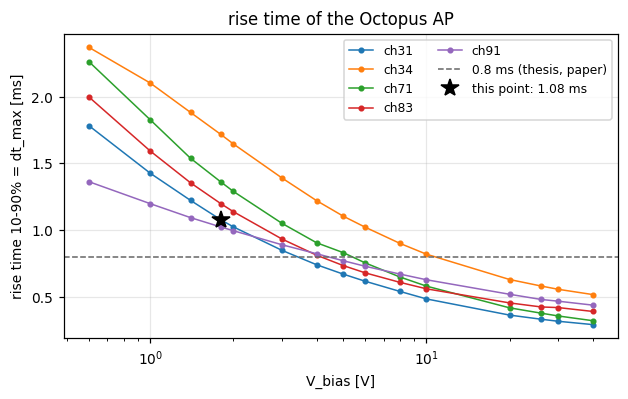

In [9]:
rows = [r for r in csv.DictReader(open(os.path.join(BASE, "amplitudes_m205.csv")))
        if int(r["channel"]) in CHANNELS and r["risetime_ms"].strip()]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for ch in CHANNELS:
    v = sorted((float(r["vbias_V"]), float(r["risetime_ms"])) for r in rows if int(r["channel"]) == ch)
    ax.plot(*zip(*v), "o-", ms=3, lw=1, label=f"ch{ch}")
ax.axhline(0.8, color="0.4", ls="--", lw=1, label="0.8 ms (thesis, paper)")
ax.plot(VBIAS, DT_MAX * 1e3, "k*", ms=12, label=f"this point: {DT_MAX * 1e3:.2f} ms")
ax.set(xscale="log", xlabel="V_bias [V]", ylabel="rise time 10-90% = dt_max [ms]", title="rise time of the Octopus AP")
ax.legend(fontsize=8, ncol=2)
rt = np.array([float(r["risetime_ms"]) for r in rows])
print(f"rise time dei {len(rt)} punti: da {rt.min():.2f} a {rt.max():.2f} ms; {np.sum(rt > 0.8)} punti sopra 0.8 ms")

## 4. Il template di addestramento (AP simulato v2)

L'addestramento non usa l'AP di Octopus (rumoroso) né il fit (che genera gli eventi: addestrare sulla verità sarebbe
barare), ma un **AP simulato**: si costruisce come l'AP vero, ma con 10 000 impulsi invece di 36–39, quindi con un
rumore di template trascurabile.

### Lo schema

```
   1   fit del WP:  s(t),  picco = 1
          │
          │   × A_LED          (mediana del filtro ottimo sugli impulsi LED del WP, uguale per tutti)
   2      │   ritardo τ        (uniforme in [0, 1 campione) = [0, 100 µs))
          ▼
       A_LED · s(t − τ)
          │
   3      │   + n(t)           (rumore gaussiano NUOVO, generato dalla NPS misurata del WP)
          ▼
       x(t) = A_LED · s(t − τ) + n(t)
          │
   4      │   − media di x sui campioni [0, 4900)      (baseline: il pretrigger, prima dell'impulso)
   5      │   / max x                                  (normalizzazione al massimo)
   6      │   traslazione di (argmax s − argmax x)     (allineamento sul massimo, campioni interi)
          ▼
       x̂ᵢ(t)          per i = 1 … 10 000
          │
   7      │   media su i,  poi / max
          ▼
         AP
```

| passo | cosa si fa | perché |
|---|---|---|
| 1 | il **fit** del WP, $s(t)$ con picco 1 | è il template liscio da cui il Monte Carlo genera anche gli eventi |
| 2 | $A_{\rm LED}\,s(t-\tau)$ | l'AP vero è fatto di impulsi LED, che cadono a caso fra due campioni |
| 3 | $+\,n(t)$, rumore gaussiano nuovo per ogni impulso, dalla NPS del WP | è lo stesso rumore del Monte Carlo. Le finestre di rumore vere prese dai dati sono un'altra modalità (`MODE = "realnoise"`), usata nella tesi solo per la sistematica |
| 4 | $-$ media dei campioni [0, 4900) | la baseline si misura dove non c'è segnale (l'impulso parte a circa 4990) |
| 5 | $/\max x$ | come Octopus: ogni impulso conta uguale |
| 6 | traslazione finché il massimo cade su quello del fit | shift e rumore spostano il massimo del singolo impulso; l'AP resta nella posizione del fit |
| 7 | media dei 10 000 impulsi, $/\max$ | il rumore residuo scende come $1/\sqrt{N}$ |

I passi 5 e 6 si possono scambiare: traslare un impulso non ne cambia il massimo. Nel codice i passi 1–6 sono
`ledv2_pulses`, che restituisce un blocco di 500 impulsi alla volta, e il 7 è `build_mc_v2`; i numeri nei commenti sono
quelli dello schema. I fotoni qui non servono: quelli del LED non sono fotoni di scintillazione, e normalizzando ogni
impulso l'ampiezza non conta.

In [10]:
show(bs.ledv2_pulses)
show(bs.build_mc_v2)
show(bs.shift_pad)

`build_simAP_injected_m205.py:311`

```python
def ledv2_pulses(channel, wp, n_pulses=N_PULSES, seed=SEED):
    """Gli impulsi dell'AP simulato v2 (passi 1-6 di build_mc_v2), a blocchi di GEN_CHUNK.
    Usata da build_mc_v2 e dal notebook tutorial, che ne mostra gli impulsi e le medie parziali."""
    nps = load_nps(channel, wp)
    amp = led_amp_of(channel, wp)
    w = 2 * np.pi * np.fft.fftfreq(WINDOW, 1.0 / SAMPLING_RATE)
    tpl = template(channel, wp, "fit")                      # 1. il fit, picco = 1
    S_raw = np.fft.fft(tpl)                                 #    NON finestrato, come in build_mc
    target = int(np.argmax(tpl))
    s = seed + 1000 * channel + wp                          # un seed per punto, come build_mc
    rng, rng_x = np.random.default_rng(s), np.random.default_rng([s, 1])
    for k in range(0, n_pulses, GEN_CHUNK):
        n = min(GEN_CHUNK, n_pulses - k)
        # 2.-3. A_LED * fit ritardato di tau + rumore generato dalla NPS
        fp, _ = sim.simulate_frequency_pulses_v2(S_raw, nps, w, n, rng, rng_x, signal_scale=amp,
                                                 dt_max=0.0, shift_max=1.0 / SAMPLING_RATE)
        p = np.fft.ifft(fp, axis=1).real
        del fp
        p -= p[:, :PRE_BASELINE].mean(axis=1, keepdims=True)                       # 4. baseline
        p /= p.max(axis=1, keepdims=True)                                          # 5. /max
        yield np.array([shift_pad(q, target - int(np.argmax(q))) for q in p])     # 6. allineamento
```

`build_simAP_injected_m205.py:334`

```python
def build_mc_v2(channel, wp, n_pulses=N_PULSES, seed=SEED):
    """AP simulato v2 = MEDIA di n_pulses impulsi SINGOLI all'ampiezza LED, trattati come si
    trattano gli impulsi veri. Per ogni impulso (ledv2_pulses):

      1. il fit del WP, picco = 1;
      2. ampiezza LED = mediana del filtro ottimo di Octopus (led_amp_of), uguale per tutti, e
         shift sub-campione tau uniforme in [0, 1 campione), come gli impulsi LED veri che cadono
         a caso fra due campioni;
      3. rumore: una realizzazione gaussiana nuova dalla NPS misurata del WP (la stessa del Monte
         Carlo; le finestre di rumore vere sono MODE = "realnoise");
      4. baseline = media del pretrigger, campioni [0, PRE_BASELINE), prima dell'impulso (che parte
         a ~4990), sottratta;
      5. normalizzazione al massimo;
      6. allineamento sul massimo: traslazione di un numero intero di campioni, senza wrap-around,
         finche' il massimo cade dove cade quello del fit. Shift e rumore spostano il massimo del
         singolo impulso; l'AP resta nella posizione del template che genera gli eventi.
    Poi:
      7. media degli n_pulses impulsi, normalizzata al massimo.
    Niente fluttuazione dei fotoni: i fotoni del LED non sono quelli di scintillazione (il
    guadagno NTL e' diverso) e, normalizzando ogni impulso, l'ampiezza non conta. Niente energia
    nella ROI: agli impulsi LED non si applica.

    Restituisce (AP normalizzato al massimo, n_pulses, A_LED [V]); il file lo salva chi chiama."""
    ap = sum(p.sum(axis=0) for p in ledv2_pulses(channel, wp, n_pulses, seed)) / n_pulses   # 7.
    return ap / ap.max(), n_pulses, led_amp_of(channel, wp)
```

`build_medianAP_maxalign_m205.py:44`

```python
def shift_pad(p, s):
    """Trasla `p` di `s` campioni (positivo = verso destra) riempiendo di zeri, senza
    wrap-around: equivalente a utility.functions.align_waveforms su una singola traccia
    (qui in numpy, cosi' il programma non ha bisogno di torch)."""
    out = np.zeros_like(p)
    if s >= 0:
        out[s:] = p[:len(p) - s] if s else p
    else:
        out[:s] = p[-s:]
    return out
```

### I passi, uno per uno
Il primo blocco di 500 impulsi rifatto a mano passo per passo, con gli stessi seed di `ledv2_pulses`. L'`assert`
controlla che alla fine sia **identico** al blocco che usa la campagna.

primo blocco identico a ledv2_pulses;  AP v2 = media di 10000 impulsi in 10 s


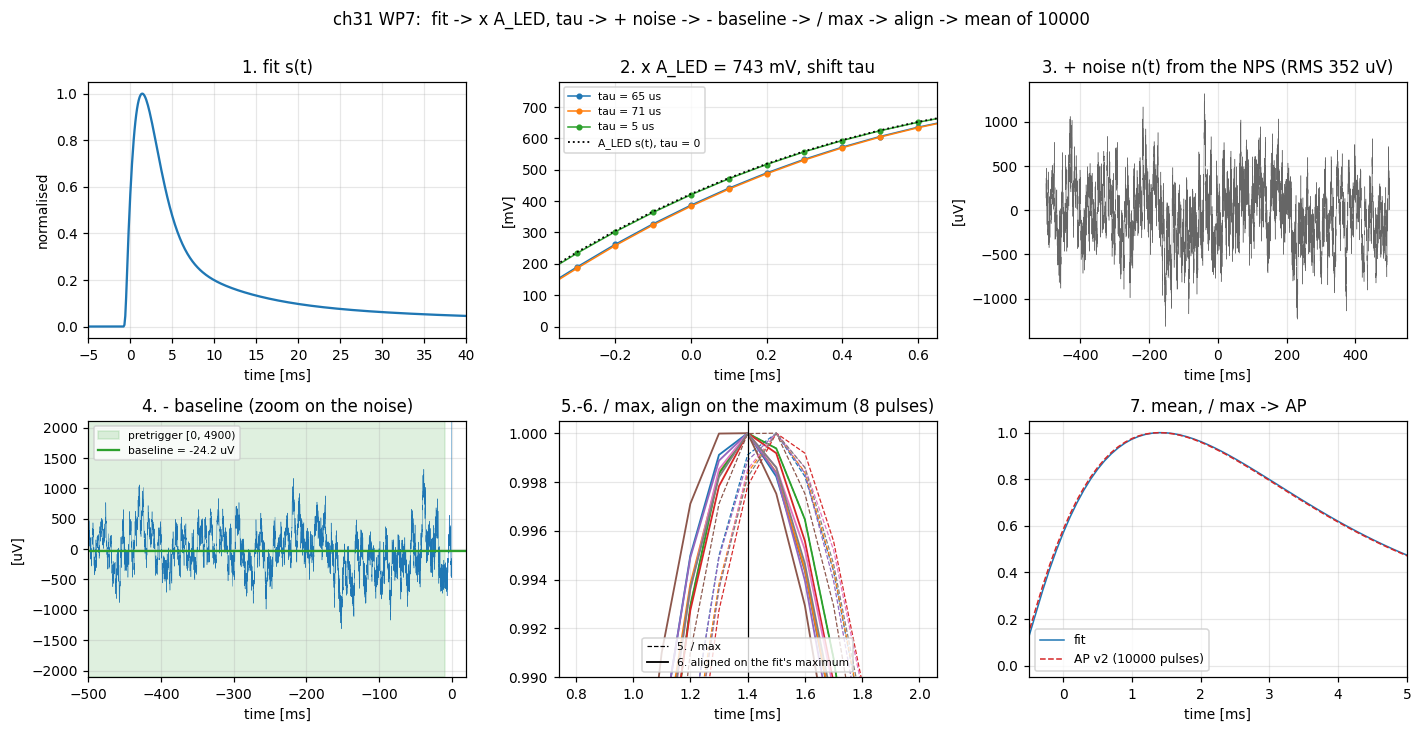

In [11]:
tpl = bs.template(CH, WP, "fit")                                     # 1. il fit, picco = 1
S_raw = np.fft.fft(tpl)
s = bs.SEED + 1000 * CH + WP                                         # i seed di ledv2_pulses
rng, rng_x = np.random.default_rng(s), np.random.default_rng([s, 1])
fp, info = sim.simulate_frequency_pulses_v2(S_raw, nps, w, bs.GEN_CHUNK, rng, rng_x, signal_scale=A_LED,
                                            dt_max=0.0, shift_max=1 / FS)
sig = np.fft.ifft(A_LED * S_raw * np.exp(-1j * w * info["tau"][:, None]), axis=1).real   # 2. A_LED s(t - tau)
x = np.fft.ifft(fp, axis=1).real                                     # 3. + rumore
del fp
base = x[:, :bs.PRE_BASELINE].mean(axis=1, keepdims=True)
x4 = x - base                                                        # 4. baseline
x5 = x4 / x4.max(axis=1, keepdims=True)                              # 5. / max
target = int(np.argmax(tpl))
shifts = target - x5.argmax(axis=1)
x6 = np.array([bs.shift_pad(q, k) for q, k in zip(x5, shifts)])      # 6. allineamento sul massimo
assert np.array_equal(x6, next(bs.ledv2_pulses(CH, WP))), "il blocco rifatto a mano non e' quello di ledv2_pulses"
t0 = time.perf_counter()
ap_v2, n_pulses, a_led = bs.build_mc_v2(CH, WP)                      # 7. media dei 10 000, / max
print(f"primo blocco identico a ledv2_pulses;  AP v2 = media di {n_pulses} impulsi in {time.perf_counter() - t0:.0f} s")

noise = x[0] - sig[0]
fig, ax = plt.subplots(2, 3, figsize=(13, 6.6))
ax = ax.ravel()
ax[0].plot(t_ms, tpl, color="C0")
ax[0].set(xlim=(-5, 40), xlabel="time [ms]", ylabel="normalised", title="1. fit s(t)")
for j in range(3):
    ax[1].plot(t_ms, sig[j] * 1e3, "o-", ms=3, lw=1, label=f"tau = {info['tau'][j] * 1e6:.0f} us")
ax[1].plot(t_ms, A_LED * tpl * 1e3, "k:", lw=1.2, label="A_LED s(t), tau = 0")
ax[1].set(xlim=(-0.35, 0.65), xlabel="time [ms]", ylabel="[mV]",
          title=f"2. x A_LED = {A_LED * 1e3:.0f} mV, shift tau")
ax[1].legend(fontsize=7)
ax[2].plot(t_ms, noise * 1e6, lw=0.3, color="0.4")
ax[2].set(xlabel="time [ms]", ylabel="[uV]", title=f"3. + noise n(t) from the NPS (RMS {noise.std() * 1e6:.0f} uV)")
ax[3].plot(t_ms, x[0] * 1e6, lw=0.3, color="C0")
ax[3].axvspan(t_ms[0], t_ms[bs.PRE_BASELINE], color="C2", alpha=0.15, label="pretrigger [0, 4900)")
ax[3].axhline(base[0, 0] * 1e6, color="C2", lw=1.5, label=f"baseline = {base[0, 0] * 1e6:+.1f} uV")
ax[3].set(xlim=(t_ms[0], 20), ylim=(-6 * noise.std() * 1e6, 6 * noise.std() * 1e6), xlabel="time [ms]", ylabel="[uV]",
          title="4. - baseline (zoom on the noise)")
ax[3].legend(fontsize=7, loc="upper left")
pk = slice(target - 6, target + 7)
for j in range(8):
    l, = ax[4].plot(t_ms[pk], x5[j, pk], "--", lw=0.8)
    ax[4].plot(t_ms[pk], x6[j, pk], "-", lw=1.2, color=l.get_color())
ax[4].axvline(t_ms[target], color="k", lw=0.8)
ax[4].plot([], [], "k--", lw=0.8, label="5. / max");  ax[4].plot([], [], "k-", lw=1.2, label="6. aligned on the fit's maximum")
ax[4].set(ylim=(0.99, 1.0005), xlabel="time [ms]", title="5.-6. / max, align on the maximum (8 pulses)")
ax[4].legend(fontsize=7, loc="lower center")
ax[5].plot(t_ms, tpl, color="C0", lw=1, label="fit")
ax[5].plot(t_ms, ap_v2, color="C3", lw=1, ls="--", label=f"AP v2 ({n_pulses} pulses)")
ax[5].set(xlim=(-0.5, 5), xlabel="time [ms]", title="7. mean, / max -> AP")
ax[5].legend(fontsize=8)
fig.suptitle(f"ch{CH} WP{WP}:  fit -> x A_LED, tau -> + noise -> - baseline -> / max -> align -> mean of {n_pulses}", y=1.0)
plt.tight_layout()

### Gli impulsi che formano l'AP
Dopo il passo 6 ogni impulso ha picco 1 e un rumore piccolo rispetto al segnale, perché all'ampiezza dei LED il
rapporto segnale/rumore è alto: a scala piena gli impulsi sembrano lo stesso, il rumore si vede solo ingrandendo.
Mediandone 10 000 il rumore scende di un fattore 100, molto sotto quello dell'AP di Octopus (mediana di circa 39
impulsi veri).

RMS del pretrigger: un impulso 5.0e-04;  AP v2 (10000 impulsi) 6.5e-06;  AP di Octopus (39 impulsi) 9.5e-05


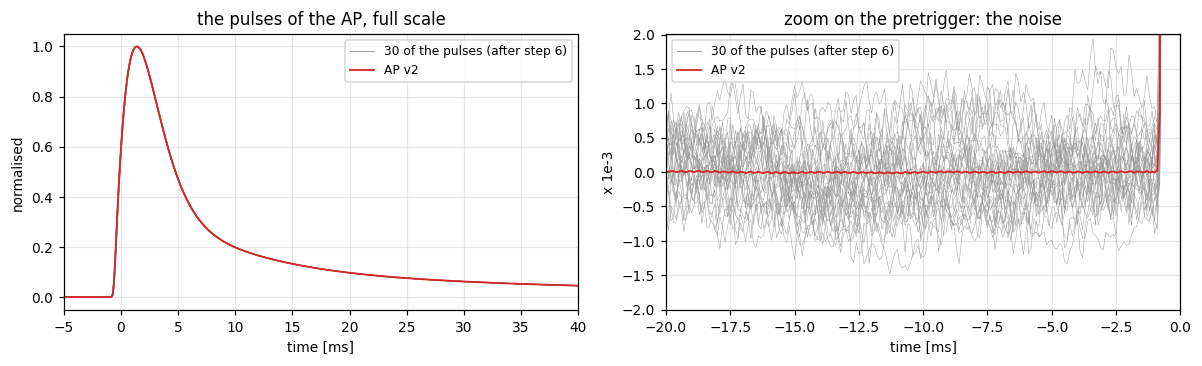

In [12]:
n_oct = len(bs.wp_selection(CH, WP)[0])                 # impulsi LED dell'AP di Octopus di questo WP
rms_pre = lambda v: float(v[:4000].std())               # rumore residuo = RMS del pretrigger
rms_1 = np.mean([rms_pre(q) for q in x6])               # un impulso (il primo blocco, gia' allineato)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for q in x6[:30]:
    ax[0].plot(t_ms, q, lw=0.4, color="0.6")
    ax[1].plot(t_ms, q * 1e3, lw=0.3, color="0.6")
for a_ in ax[:2]:
    a_.plot([], [], lw=0.6, color="0.6", label="30 of the pulses (after step 6)")
ax[0].plot(t_ms, ap_v2, color="C3", lw=1.2, label="AP v2")
ax[0].set(xlim=(-5, 40), xlabel="time [ms]", ylabel="normalised", title="the pulses of the AP, full scale")
ax[1].plot(t_ms, ap_v2 * 1e3, color="C3", lw=1.2, label="AP v2")
ax[1].set(xlim=(-20, 0), ylim=(-4 * rms_1 * 1e3, 4 * rms_1 * 1e3), xlabel="time [ms]", ylabel="x 1e-3",
          title="zoom on the pretrigger: the noise")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8, loc="upper left")
plt.tight_layout()
print(f"RMS del pretrigger: un impulso {rms_1:.1e};  AP v2 ({n_pulses} impulsi) {rms_pre(ap_v2):.1e};  "
      f"AP di Octopus ({n_oct} impulsi) {rms_pre(ap_oct):.1e}")

### Perché allineare
Lo shift $\tau$ ritarda l'impulso di mezzo campione in media e sposta il suo massimo al campione successivo in molti
casi. Senza allineamento la media è ritardata e il fronte di salita è più lento di quello del fit. L'allineamento su
campioni interi riporta il massimo al suo posto, ma non può correggere la frazione di campione: resta una differenza
più piccola, di segno opposto. Succede lo stesso allineando sul massimo gli impulsi LED veri.

traslazioni: {-1: 347, 0: 153}


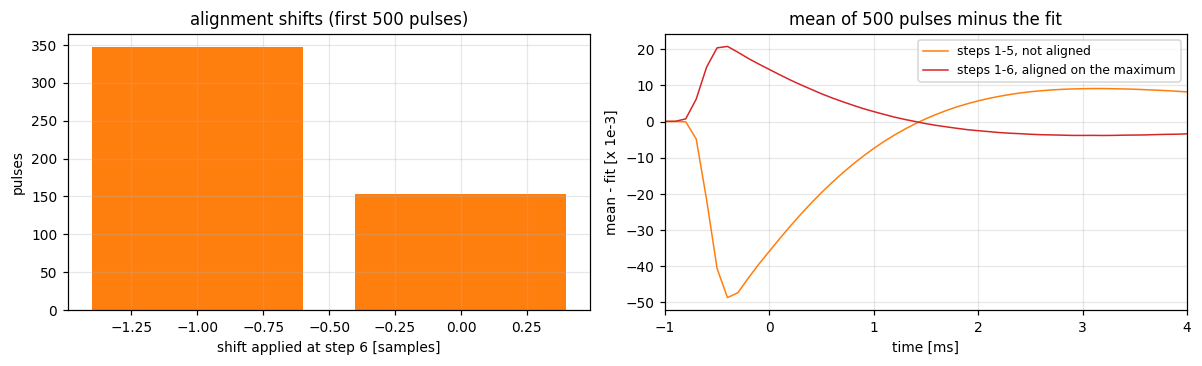

In [13]:
v, n = np.unique(shifts, return_counts=True)
ap_noalign, ap_align = x5.mean(axis=0), x6.mean(axis=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(v, n, color="C1")
ax[0].set(xlabel="shift applied at step 6 [samples]", ylabel="pulses", title=f"alignment shifts (first {len(shifts)} pulses)")
for a_, lab, c in ((ap_noalign, "steps 1-5, not aligned", "C1"), (ap_align, "steps 1-6, aligned on the maximum", "C3")):
    ax[1].plot(t_ms, (a_ / a_.max() - tpl) * 1e3, lw=1, color=c, label=lab)
ax[1].set(xlim=(-1, 4), xlabel="time [ms]", ylabel="mean - fit [x 1e-3]", title=f"mean of {len(shifts)} pulses minus the fit")
ax[1].legend(fontsize=8)
plt.tight_layout()
print("traslazioni:", {int(a): int(b) for a, b in zip(v, n)})
del sig, x, x4

### L'AP v2 accanto agli altri template

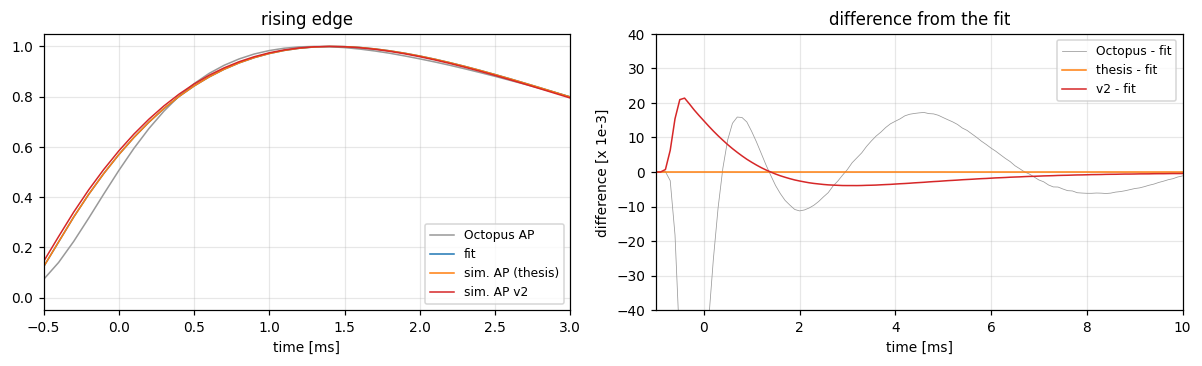

In [14]:
ap_old = np.load(os.path.join(BASE, "m205_AP_sim", f"ch{CH}", f"simAP_APsimfit10000led_ch{CH}_wp{WP}.npy"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for v_, lab, c in ((ap_oct, "Octopus AP", "0.6"), (fit, "fit", "C0"), (ap_old, "sim. AP (thesis)", "C1"), (ap_v2, "sim. AP v2", "C3")):
    ax[0].plot(t_ms, v_, lw=1, color=c, label=lab)
ax[0].set(xlim=(-0.5, 3), ylim=(-0.05, 1.05), xlabel="time [ms]", title="rising edge"); ax[0].legend(fontsize=8)
ax[1].plot(t_ms, (ap_oct - fit) * 1e3, lw=0.5, color="0.6", label="Octopus - fit")
ax[1].plot(t_ms, (ap_old - fit) * 1e3, lw=1, color="C1", label="thesis - fit")
ax[1].plot(t_ms, (ap_v2 - fit) * 1e3, lw=1, color="C3", label="v2 - fit")
ax[1].set(xlim=(-1, 10), ylim=(-40, 40), xlabel="time [ms]", ylabel="difference [x 1e-3]", title="difference from the fit")
ax[1].legend(fontsize=8)
plt.tight_layout()

### Gli spettri di potenza
L'addestramento lavora in frequenza: il filtro ottimo e il modello analitico pesano ogni frequenza con
$|S_k|^2/\mathrm{NPS}_k$ (sez. 2). Qui gli spettri di potenza $|S_k|^2$ dell'AP di Octopus, del fit e dell'AP v2, con la
stessa finestra di Hann dell'addestramento (`compute_H`), e il loro rapporto con quello del fit.

Fino a qualche centinaio di Hz i tre spettri coincidono. Più in alto l'AP v2 è il fit moltiplicato per
$\mathrm{sinc}^2(f/f_s)$: è la media sulla frazione di campione che resta dopo l'allineamento, distribuita su un intero
campione. Sopra circa 3 kHz, dove il fit ha meno di un decimilionesimo della potenza a bassa frequenza, si vede anche il
rumore residuo dell'AP v2 (le righe del rumore). L'AP di Octopus si allontana dal fit già sopra qualche centinaio di Hz
(+27% a 300 Hz, −93% a 2 kHz), e sopra 3 kHz è dominato dal rumore dei circa 39 impulsi da cui è fatto.

  300 Hz:  Octopus / fit = 1.273,  AP v2 / fit = 0.997,  sinc^2 = 0.997
 1000 Hz:  Octopus / fit = 0.365,  AP v2 / fit = 0.966,  sinc^2 = 0.968
 2000 Hz:  Octopus / fit = 0.074,  AP v2 / fit = 0.865,  sinc^2 = 0.875
 3000 Hz:  Octopus / fit = 0.312,  AP v2 / fit = 0.723,  sinc^2 = 0.737


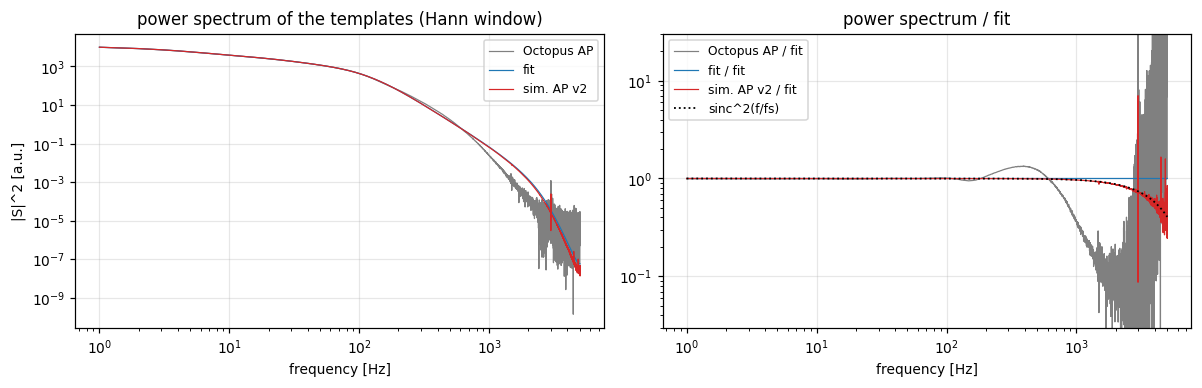

In [15]:
templates = ((ap_oct, "Octopus AP", "0.5"), (fit, "fit", "C0"), (ap_v2, "sim. AP v2", "C3"))
P = {lab: np.abs(an.compute_H(v_, nps, np.hanning, sampling_rate=FS)[0][:half]) ** 2   # S = FFT(template * Hann)
     for v_, lab, _ in templates}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for _, lab, c in templates:
    ax[0].loglog(f[1:], P[lab][1:], lw=0.8, color=c, label=lab)
    ax[1].loglog(f[1:], P[lab][1:] / P["fit"][1:], lw=0.8, color=c, label=f"{lab} / fit")
ax[1].loglog(f[1:], np.sinc(f[1:] / FS) ** 2, "k:", lw=1.2, label="sinc^2(f/fs)")
ax[0].set(xlabel="frequency [Hz]", ylabel="|S|^2 [a.u.]", title="power spectrum of the templates (Hann window)")
ax[1].set(xlabel="frequency [Hz]", ylim=(0.03, 30), title="power spectrum / fit")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8, loc="upper left")
plt.tight_layout()
for fr in (300, 1000, 2000, 3000):
    i = np.searchsorted(f, fr)
    print(f"{fr:5d} Hz:  Octopus / fit = {P['Octopus AP'][i] / P['fit'][i]:.3f},  AP v2 / fit = {P['sim. AP v2'][i] / P['fit'][i]:.3f},"
          f"  sinc^2 = {np.sinc(fr / FS) ** 2:.3f}")

## 5. Addestramento: filtro ottimo e due filtri di banda (algoritmo originale)

Il modello analitico del paper, invariato:

- filtro ottimo $H = S^*/N$, e due filtri di banda reali e positivi $f_1, f_2$, addestrabili;
- discriminante $Y = \max_t (f_1 H X)(t) \,/\, \max_t (f_2 H X)(t)$: per un singolo vale circa 1, per un pile-up meno di 1;
- per ogni pile-up $(\Delta t, r)$: $\mu_Y(\Delta t, r)$ dal template senza rumore, $\sigma_Y$ propagando il rumore al
  primo ordine (`compute_mu_sigma`);
- il taglio lascia passare il 90% dei singoli, $Y_{cut} = 1 - N_\sigma \sigma_{Y,0}$ con $N_\sigma = \Phi^{-1}(0.9)$; la
  probabilità che un pile-up passi è $A(\Delta t, r) = 1 - \Phi\big((Y_{cut} - \mu_Y)/\sigma_Y\big)$ (`compute_A`);
- $J$ = media di $A$ su $\Delta t$ uniforme in $[0, \Delta t_{\max}]$ (100 punti) e su $r$ pesato con $f_R$ (`compute_J`);
- $\mathrm{BI}_{an} = K(\Delta t_{\max})\cdot J$; si minimizza $J$ con Adam (lr $10^{-2}$) su $|f_1|, |f_2|$ (`optimize_filters`).

Fotoni, energia e shift entrano solo nel Monte Carlo, come nel paper: il rapporto MC/analitico ne misura l'effetto.

In [16]:
show(an.compute_mu_sigma)
show(an.compute_A)
show(an.compute_J)
show(an.optimize_filters)
show(ab.build_shared)
show(ab.estimate_BI_for_wp)

`src/analysis.py:236`

```python
def compute_mu_sigma(f1, f2, S_H_delayed, r, S_H, S2_over_nps, signal_amp, return_all=False):
    """
    Computes the mean (mu) and standard deviation (sigma) for the given filters and signal.

    Args:
        f1 (torch.Tensor): First filter tensor.
        f2 (torch.Tensor): Second filter tensor.
        S_H_delayed (torch.Tensor): Weighted signal delayed tensor.
        r (torch.Tensor): Ratio tensor.
        S_H (torch.Tensor): Weighted signal tensor.
        S2_over_nps (torch.Tensor): Normalized spectrum tensor.
        signal_amp (float): Signal amplitude.
        return_all (bool, optional): If True, returns additional intermediate values. Defaults to False.

    Returns:
        tuple:
            - muY (torch.Tensor): Ratio of the maximum amplitudes of the two signals.
            - sigmaY (torch.Tensor): Standard deviation of the ratio.
            - (Optional) Additional intermediate values if `return_all` is True.
    """
    s_H_1 = torch.fft.ifft(S_H * f1).real
    s_H_delayed_1 = torch.fft.ifft(S_H_delayed * f1, dim = -1).real
    s_pileup_1 = (1-r[:, None, None]) * s_H_1 + r[:, None, None] * s_H_delayed_1[None, :, :]
    mu1 = torch.max(s_pileup_1.real, dim = -1).values
    s_H_2 = torch.fft.ifft(S_H * f2).real
    s_H_delayed_2 = torch.fft.ifft(S_H_delayed * f2, dim = -1).real
    s_pileup_2 = (1-r[:, None, None]) * s_H_2 + r[:, None, None] * s_H_delayed_2[None, :, :]
    mu2 = torch.max(s_pileup_2.real, dim = -1).values
    muY = mu1 / mu2
    var1, var2, cov12 = compute_vars(S2_over_nps, f1, f2)
    sigmaY = compute_sigma_ratio(mu1, mu2, var1, var2, cov12) / signal_amp
    if return_all:
        return muY, sigmaY, mu1, mu2, var1, var2, cov12
    else:
        return muY, sigmaY
```

`src/analysis.py:273`

```python
def compute_A(muY, sigmaY, N_sigma=1.28):
    """
    Computes the acceptance (A).

    Args:
        muY (torch.Tensor): Ratio of the maximum amplitudes of the two signals.
        sigmaY (torch.Tensor): Standard deviation of the ratio.
        N_sigma (float, optional): Sigma threshold. Defaults to 1.28.

    Returns:
        torch.Tensor: Computed probability value.
    """
    return 1 - norm.cdf((1-muY-N_sigma*sigmaY[0, 0]) / sigmaY)
```

`src/analysis.py:288`

```python
def compute_J(f1, f2, S_H_delayed, r, S_H, S2_over_nps, signal_amp, ratio_distribution, N_sigma=1.28):
    """
    Computes the J metric for the given inputs.

    Args:
        f1 (torch.Tensor): First filter tensor.
        f2 (torch.Tensor): Second filter tensor.
        S_H_delayed (torch.Tensor): Weighted signal delayed tensor.
        r (torch.Tensor): Ratio tensor.
        S_H (torch.Tensor): Weighted signal tensor.
        S2_over_nps (torch.Tensor): Normalized spectrum tensor.
        signal_amp (float): Signal amplitude.
        ratio_distribution (torch.Tensor): Ratio distribution tensor.
        N_sigma (float, optional): Sigma threshold. Defaults to 1.28.

    Returns:
        torch.Tensor: Computed J metric.
    """
    muY, sigmaY = compute_mu_sigma(f1, f2, S_H_delayed, r, S_H, S2_over_nps, signal_amp)
    A = compute_A(muY, sigmaY, N_sigma=N_sigma)
    return torch.mean(A*ratio_distribution[:, None]).real
```

`src/analysis.py:311`

```python
def optimize_filters(S, H_unit, w, t, r, nps, signal_amp, ratio_distribution, N_sigma = 1.28, n_trials = 1000,
                     f1_init=None,f2_init=None,verbose = True):
    """
    Optimizes two filters (f1 and f2) to maximize the J metric using gradient-based optimization.

    Args:
        S (torch.Tensor): Input signal tensor.
        H_unit (torch.Tensor): Unit response tensor.
        w (torch.Tensor): Frequency tensor.
        t (torch.Tensor): Time tensor.
        r (torch.Tensor): Ratio tensor.
        nps (torch.Tensor): Baseline spectrum tensor.
        signal_amp (float): Signal amplitude.
        ratio_distribution (torch.Tensor): Ratio distribution tensor.
        N_sigma (float, optional): Sigma threshold for the J metric. Defaults to 1.28.
        n_trials (int, optional): Number of optimization steps. Defaults to 1000.

    Returns:
        tuple:
            - f1 (numpy.ndarray): Optimized first filter.
            - f2 (numpy.ndarray): Optimized second filter.
            - J_values (list): List of J metric values during optimization.
    """
    # Precompute constants required for optimization
    S_H_delayed, S_H, S2_over_nps = precompute_constants(S, H_unit, w, t, nps)
    # Initialize filter parameters as complex tensors
    n = len(H_unit)
    f1_init = torch.rand(n//2+1, dtype = torch.float) if f1_init is None else f1_init
    f2_init = torch.rand(n//2+1, dtype = torch.float) if f2_init is None else f2_init
    if len(f1_init) > n//2+1:
        f1_init = f1_init[:n//2+1]
    if len(f2_init) > n//2+1:
        f2_init = f2_init[:n//2+1]
    f1_param = torch.nn.Parameter(f1_init)
    f2_param = torch.nn.Parameter(f2_init)

    # Set up the optimizer
    optimizer = torch.optim.Adam([f1_param, f2_param], lr = 1e-2)
    J_values = []  # To store J metric values during optimization
    f1 = torch.abs(f1_param)
    f2 = torch.abs(f2_param)
    f1 = torch.cat([f1, f1[1:-1].flip(0)])
    f2 = torch.cat([f2, f2[1:-1].flip(0)])
    for step in range(n_trials):
        optimizer.zero_grad()  # Reset gradients
        # Enforce positivity of the filters
        f1 = torch.abs(f1_param)
        f2 = torch.abs(f2_param)
        f1 = torch.cat([f1, f1[1:-1].flip(0)])
        f2 = torch.cat([f2, f2[1:-1].flip(0)])
        # Normalize filters such that mean(|f_i * H * S|) = 1
        norm1 = torch.mean(torch.abs(f1 * H_unit * S))
        norm2 = torch.mean(torch.abs(f2 * H_unit * S))
        f1 = f1 / norm1
        f2 = f2 / norm2
        # Compute the J metric
        J = compute_J(f1, f2, S_H_delayed, r, S_H, S2_over_nps, signal_amp, ratio_distribution, N_sigma = N_sigma)
        J_values.append(J.item())  # Store the current J value

        # Backpropagation and update filter parameters
        J.backward()
        optimizer.step()

        # Uncomment the following lines to print progress every 100 steps
        if step % 100 == 0 and verbose:
            print(f"Step {step}: J = {J.item():.6f}")
    print(f"Step {step}: J = {J.item():.6f}")
    # Convert optimized filters to numpy arrays
    f1 = np.abs(f1.detach().numpy())
    f2 = np.abs(f2.detach().numpy())
    return f1, f2, J_values
```

`analyse_BI_m205.py:324`

```python
def build_shared(device, dt_max) -> dict:
    """Quantità condivise (poco costose): ricalcolate da ogni worker. dt_max [s] = ritardo
    massimo del pile-up del punto (fn.dt_max_for)."""
    import torch
    from scipy.stats import norm
    from utility.double_beta_spectrum import pdf_ratio2b

    N_sigma = float(norm.ppf(1 - (1 - ACCEPTANCE)))
    ratio_distribution = pdf_ratio2b(np.linspace(R_MIN, R_MAX, N_R))
    ratio_distribution /= np.mean(ratio_distribution)
    return {
        "N_sigma": N_sigma,
        "dt_max": dt_max,
        "t_torch": torch.linspace(T_MIN, dt_max, N_T, dtype=torch.cfloat, device=device),
        "r_torch": torch.linspace(R_MIN, R_MAX, N_R, dtype=torch.cfloat, device=device),
        "ratio_distribution_torch": torch.tensor(
            ratio_distribution, dtype=torch.cfloat, device=device
        ),
    }
```

`analyse_BI_m205.py:345`

```python
def estimate_BI_for_wp(channel, wp, vbias, meanpulse, nps, signal_amp,
                       samp_rate, shared, device) -> dict:
    import torch
    import src.analysis as an
    import utility.functions as fn

    # ── Optimal filter ────────────────────────────────────────────────────────
    S, w, H_unit = an.compute_H(meanpulse, nps, np.hanning, sampling_rate=samp_rate)
    sigma_analytic = an.compute_sigma_OF(S, nps)

    # ── Figura di merito temporale (Cramer-Rao sul tempo di arrivo) ────────────
    #   beta = banda RMS pesata sul rumore del template [Hz]:
    #     beta = sigma_OF / sigma_mod ,  sigma_mod = compute_sigma_OF(f*S, nps)
  
    sigma_mod = float(an.compute_sigma_OF(w * S, nps))
    beta_Hz = (float(sigma_analytic) / sigma_mod
               if np.isfinite(sigma_mod) and sigma_mod > 0 else float("nan"))
    SNR = float(signal_amp / sigma_analytic)
    rho_t = SNR * beta_Hz                                 # SNR * beta [Hz]

    # ── Torch tensors ─────────────────────────────────────────────────────────
    def to_t(arr, dtype=torch.cfloat):
        return torch.tensor(np.asarray(arr), dtype=dtype, device=device)

    S_torch = to_t(S)
    H_unit_torch = to_t(H_unit)
    w_torch = to_t(w)
    nps_torch = to_t(nps)
    signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32, device=device)

    # ── Optimise filters ──────────────────────────────────────────────────────
    t_train = time.perf_counter()          # tempo del solo addestramento -> colonna train_s
    f1_opt, f2_opt, J_values = an.optimize_filters(
        S_torch, H_unit_torch, w_torch,
        shared["t_torch"], shared["r_torch"], nps_torch,
        signal_amp_torch, shared["ratio_distribution_torch"],
        N_sigma = shared["N_sigma"],
        n_trials = N_TRIALS,
        verbose = False,
    )                                      # algoritmo originale dell'autore (vedi src/analysis.py)
    train_s = time.perf_counter() - t_train

    BI_estimate = float(J_values[-1]) * fn.K_for(shared["dt_max"])   # K della finestra [0, dt_max]

    return {
        "channel": channel,
        "wp": wp,
        "vbias": vbias,
        "signal_amp": float(signal_amp),
        "sigma_analytic": float(sigma_analytic),
        "SNR": SNR,
        "beta_Hz": beta_Hz,
        "rho_t": rho_t,
        "template": TEMPLATE_SOURCE,
        "BI": float(BI_estimate),
        "J_final": float(J_values[-1]),
        "n_trials": N_TRIALS,
        "train_s": round(train_s, 1),
        # Storia dell'addestramento (non entra nel CSV): J passo per passo, per vedere SE e
        # DOVE si appiana. Il filtro ottimo non ha lambda, il kernel S*/NPS e' fisso.
        "J_hist": np.asarray(J_values, dtype=float),
        # Filtri di banda e kernel (qui il filtro ottimo H_unit), salvati a parte
        # come .npy in FILTERS_DIR; non entrano nel BI CSV (append_row_to_csv tiene
        # solo CSV_FIELDNAMES). Filtro totale applicato ai dati: g_i = f_i * H_unit.
        "f1": f1_opt,          # gia' numpy, |f| normalizzato
        "f2": f2_opt,
        "kernel": np.asarray(H_unit),
    }
```

In [17]:
device = torch.device("cpu")
ab.N_TRIALS = N_STEPS                       # la campagna usa 500 passi
torch.manual_seed(0)                        # inizializzazione casuale dei filtri, riproducibile
t0 = time.perf_counter()
res = ab.estimate_BI_for_wp(str(CH), WP, VBIAS, ap_v2, nps, A_ROI, FS, ab.build_shared(device, DT_MAX), device)
print(f"{N_STEPS} passi in {time.perf_counter() - t0:.0f} s:  J = {res['J_final']:.4f},  "
      f"BI analitico = {res['BI']:.3e} counts/(keV kg yr),  SNR_OF = {res['SNR']:.1f}")

Step 39: J = 0.255377
40 passi in 103 s:  J = 0.2554,  BI analitico = 9.126e-05 counts/(keV kg yr),  SNR_OF = 19.9


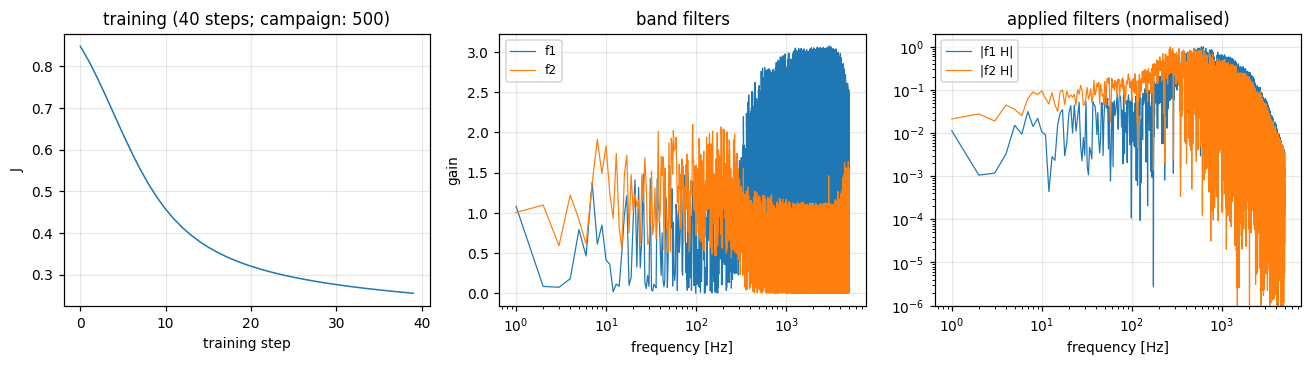

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].plot(res["J_hist"], lw=1)
ax[0].set(xlabel="training step", ylabel="J", title=f"training ({N_STEPS} steps; campaign: 500)")
for k_, c in (("f1", "C0"), ("f2", "C1")):
    ax[1].semilogx(f[1:], res[k_][1:half], lw=0.8, color=c, label=k_)
    g = np.abs(res[k_] * res["kernel"])[:half]
    ax[2].loglog(f[1:], g[1:] / g[1:].max(), lw=0.8, color=c, label=f"|{k_} H|")
ax[1].set(xlabel="frequency [Hz]", ylabel="gain", title="band filters"); ax[1].legend(fontsize=8)
ax[2].set(xlabel="frequency [Hz]", ylim=(1e-6, 2), title="applied filters (normalised)"); ax[2].legend(fontsize=8)
plt.tight_layout()

## 6. Il Monte Carlo

Ogni evento si genera direttamente nel dominio delle frequenze, dal **fit** (la "verità"):

$$X_k = A_i\,S_k\,\big[(1-r) + r\,e^{-i\omega_k \Delta t}\big]\,e^{-i\omega_k \tau} + N_k$$

| grandezza | distribuzione | dove |
|---|---|---|
| rumore $N_k$ | gaussiano complesso, $E|N_k|^2 = 2\,\mathrm{NPS}_k$; la parte reale dell'IFFT ne dimezza la potenza | tesi |
| ripartizione $r$ | $f_R \propto r^6(1-r)^6 P(rQ)P((1-r)Q)$: due 2νββ con somma $Q_{\beta\beta}$ | tesi |
| ritardo $\Delta t$ | uniforme in $[0, \Delta t_{\max}]$, $\Delta t_{\max}$ = rise time del punto; 0 per i singoli | **nuovo** $\Delta t_{\max}$ |
| energia somma $E$ | spettro somma di due 2νββ in [3019, 3049] keV; l'ampiezza è $A\,E/Q$ | **nuovo** |
| ampiezza $A_i$ | gaussiana di media $A\,E/Q$ e $\sigma = (A E/Q)/\sqrt{N_\gamma E/Q}$ (fotoni) | **nuovo**, `detector_sigma` |
| shift $\tau$ | uniforme in [0, 100 µs), applicato solo al segnale | **nuovo** |

$A$ è l'ampiezza nella ROI (sez. 1.2) e $N_\gamma$ i fotoni a $Q_{\beta\beta}$ del canale (sez. 1.3).

**Eventi appaiati.** Singoli e pile-up si generano con lo stesso seed: hanno lo stesso rumore, la stessa energia, la
stessa ampiezza, lo stesso $r$ e lo stesso $\tau$, cambia solo il ritardo del secondo impulso. Le aggiunte usano un
secondo generatore (seed `[seed, 1]`), così non spostano le estrazioni del primo.

Poi `get_PSD_interpole` calcola $Y$ per ogni evento: sottrae la **baseline**, applica $f_1 H$ e $f_2 H$, cerca il
massimo entro ±`jitter_max` campioni dal centro (abbastanza da contenere il picco del secondo impulso, `point_dt`) e lo
raffina con un'interpolazione cubica. `bi_from` mette il taglio al 10° percentile dei singoli e conta i pile-up sotto
il taglio: $\mathrm{BI}_{MC} = K(\Delta t_{\max})\,(1 - r_p)$.

**La baseline.** Nella tesi `get_PSD_interpole` toglieva `np.mean(pulses[:4900], axis=-1)`: l'indice taglia le
*righe* (gli eventi), non i campioni, quindi la baseline era la media di **tutta** la finestra, impulso compreso.
Ora (`pre_baseline=True`, il default di `simulate_psd_v2`) è la media dei campioni [0, 4900), prima dell'impulso.
L'effetto sul BI di questo punto è nel confronto appaiato in fondo.

In [19]:
show(sim.simulate_frequency_pulses)          # l'originale (invariato)
show(sim.simulate_frequency_pulses_v2)       # la variante con fotoni, energia e shift
show(dbs.build_sum_energy_distribution)

`src/simulation.py:37`

```python
def simulate_frequency_pulses(S, nps, detector_sigma, w, nsim=10000, seed=1234, signal_scale=0.002, dt_max=8e-4,
                              fold_ratio=False):
    """
    Simulate frequency-domain pulse realizations with stochastic phase and noise.

    Each realization represents a possible frequency-domain signal including:
      - A deterministic spectral shape `S`
      - Randomized energy sharing between two sub-events (via `inverse_cdf_ratio2b`)
      - Random emission time differences (Δt)
      - Additive complex Gaussian noise with baseline spectrum `nps`

    Parameters
    ----------
    S : ndarray, shape (M,)
        Deterministic signal spectrum in frequency domain.
    nps : ndarray, shape (M,)
        Baseline noise power spectrum (frequency-dependent variance).
    detector_sigma : float
        Detector-level energy fluctuation amplitude.
    w : ndarray, shape (M,)
        Frequency vector (radians per second).
    nsim : int, optional
        Number of Monte Carlo realizations (default: 10,000).
    seed : int, optional
        Random number generator seed (default: 1234).
    signal_scale : float, optional
        Base amplitude scaling factor for the deterministic signal (default: 0.002).
    dt_max : float, optional
        Maximum random time delay (seconds) between sub-events (default: 8e-4).
    fold_ratio : bool, optional
        If True, fold the sharing ratio onto [0, 0.5] with r -> min(r, 1-r), i.e. the convention
        of the analytical J (default: False, full range as sampled from the 2b distribution).

    Returns
    -------
    fpulses : ndarray, shape (nsim, M)
        Simulated complex frequency-domain signals for each realization.
    signal_freq : ndarray, shape (nsim, M)
        Deterministic (noise-free) signal component for each realization.
    noise_freq : ndarray, shape (nsim, M)
        Random noise component in frequency domain.
    generated_r : ndarray, shape (nsim,)
        Random energy-sharing ratios (R = E1 / E2).
    generated_dt : ndarray, shape (nsim,)
        Random inter-event time delays (seconds).
    """
    rng = np.random.default_rng(seed)
    M = S.size

    # --- complex Gaussian noise with spectral shape ---
    # E|N_k|^2 = 2*nps_k: il rumore in frequenza NON e' hermitiano, quindi il .real dell'ifft
    # (piu' sotto) ne dimezza la varianza e in tempo si ottiene var = sum(nps)/M^2, cioe' la
    # convenzione in cui vale sigma_OF = 1/sqrt(sum |S|^2/nps).
    # VERIFICATO su m205 ch91 WP15 con lo stimatore OF esatto: sigma simulata / sigma_OF = 0.99.
    # Prima qui c'era un fattore sqrt(2) in piu' (E|N|^2 = 4*nps) che iniettava sqrt(2) di
    # rumore di troppo, gonfiando del ~40% le larghezze e quindi il BI da simulazione.
    complex_gauss = rng.normal(size=(nsim, M)) + 1j * rng.normal(size=(nsim, M))
    noise_freq = complex_gauss * np.sqrt(nps[None, :])  # (nsim, M)

    # --- deterministic signal per realization ---
    amplitude = rng.normal(loc=signal_scale, scale=detector_sigma, size=nsim)[:, None]
    signal_freq = amplitude * S[None, :]  # (nsim, M)

    # --- random energy-sharing ratios and delays ---
    generated_r = inverse_cdf_ratio2b(rng.random(nsim))
    if fold_ratio:
        # r e 1-r descrivono lo stesso pile-up scambiando i due eventi: ripiegando su [0, 0.5]
        # si usa la stessa convenzione del calcolo ANALITICO (r_torch = linspace(0, 0.5, N_R)).
        generated_r = np.minimum(generated_r, 1.0 - generated_r)
    generated_dt = rng.uniform(0, dt_max, nsim)

    # --- phase modulation due to inter-event timing ---
    exp_term = np.exp(-1j * w * generated_dt[:, None])  # (nsim, M)
    phase = (1 - generated_r[:, None]) + generated_r[:, None] * exp_term
    # --- final frequency-domain realizations ---
    fpulses = signal_freq * phase + noise_freq
    return fpulses, signal_freq, noise_freq, generated_r, generated_dt
```

`src/simulation.py:120`

```python
def simulate_frequency_pulses_v2(S, nps, w, nsim, rng, rng_x, signal_scale, dt_max,
                                 n_photons=None, e_roi=None, q_value=3.034, shift_max=0.0):
    """
    Variante v2 di simulate_frequency_pulses (2026-10-25): gli stessi eventi, piu' le tre aggiunte
    della generazione degli eventi del paper (Berest 2026, sez. 4.2). L'ORIGINALE non si tocca:
    questa funzione la chiama e lavora solo su cio' che le passa e su cio' che ne riceve.

    Ogni aggiunta e' una riga e si spegne con il suo argomento a None / 0:

      1. ENERGIA NELLA ROI (e_roi = (E_lo, E_hi) in MeV). L'energia somma E dell'evento si estrae
         dallo spettro somma di due 2nbb ristretto alla ROI (build_sum_energy_distribution, la
         ricetta di Ahmine 2023). La luce e' proporzionale all'energia: l'ampiezza diventa
         A * E/Q. Il rapporto r resta estratto dalla f_R originale, costruita a E = Q: fra 3019 e
         3049 keV la f_R cambia dello 0.4% (distanza di variazione totale).
      2. FLUTTUAZIONE DEL NUMERO DI FOTONI (n_photons = fotoni assorbiti a E = Q). Come nel
         codice originale, con detector_sigma: l'ampiezza dell'evento e' una gaussiana di media
         A E/Q e sigma = (A E/Q) / sqrt(n_photons E/Q), cioe' Poisson nell'approssimazione
         gaussiana (~200 fotoni). E' UN fattore per evento: i due impulsi di un pile-up
         fluttuano insieme e r resta esatto.
      3. SHIFT SUB-CAMPIONE (shift_max in s; 1e-4 = un campione a 10 kHz). L'impulso arriva in un
         istante continuo, il campionamento ha una griglia fissa: l'inizio cade a caso fra due
         campioni. Tutto il SEGNALE (i due impulsi) si ritarda di tau ~ U(0, shift_max), cioe'
         si moltiplica per e^{-i w tau}; il rumore resta quello estratto. Stessa distribuzione
         dello shift di simulate_frequency_pulses_fixed_dt_r, qui con un generatore con seed.

    Due generatori:
      rng   -> quello dell'originale (rumore, ampiezza, r, dt) con le stesse estrazioni nello
               stesso ordine: con le tre aggiunte spente l'uscita e' IDENTICA all'originale.
      rng_x -> E e tau, in quest'ordine. Separato, cosi' le aggiunte non spostano le estrazioni
               di rng; con lo stesso seed, singoli e pile-up ricevono gli stessi E e tau.

    Parameters
    ----------
    S, nps, w : come in simulate_frequency_pulses.
    nsim : int
        Numero di eventi.
    rng, rng_x : numpy.random.Generator
    signal_scale : float
        Ampiezza A a E = Q (l'ampiezza di ROI).
    dt_max : float
        Ritardo massimo del pile-up [s]; 0 -> impulsi singoli.

    Returns
    -------
    fpulses : ndarray, shape (nsim, M)
        Eventi nel dominio delle frequenze, come l'originale.
    info : dict
        Per evento: "energy" [MeV], "amp" (ampiezza media, prima della fluttuazione),
        "sigma" (della fluttuazione), "tau" [s], "r", "dt" [s].
    """
    e = (_sum_energy_icdf(*e_roi)(rng_x.random(nsim)) if e_roi is not None
         else np.full(nsim, q_value))                         # 1. energia somma [MeV]
    amp = signal_scale * (e / q_value)                        #    luce proporzionale all'energia
    sigma = (amp / np.sqrt(n_photons * (e / q_value)) if n_photons
             else np.zeros(nsim))                             # 2. Poisson sui fotoni
    fpulses, _, noise, r, dt = simulate_frequency_pulses(S, nps, sigma, w, nsim=nsim, seed=rng,
                                                         signal_scale=amp, dt_max=dt_max)
    tau = rng_x.uniform(0.0, shift_max, nsim) if shift_max else np.zeros(nsim)
    if shift_max:                                             # 3. shift del solo segnale
        fpulses = (fpulses - noise) * np.exp(-1j * w[None, :] * tau[:, None]) + noise
    return fpulses, dict(energy=e, amp=amp, sigma=sigma, tau=tau, r=r, dt=dt)
```

`utility/double_beta_spectrum.py:166`

```python
def build_sum_energy_distribution(e_lo, e_hi, n_grid=301):
    """
    Distribuzione dell'energia SOMMA E = E1 + E2 di due decadimenti 2nbb indipendenti, ristretta
    alla finestra [e_lo, e_hi] (MeV). E' la ricetta di Ahmine et al. 2023 (EPJC 83, 373, sez. 4.2),
    citata dal paper per i suoi eventi: si estraggono due energie dallo spettro g e si tengono le
    coppie la cui somma cade nella ROI. La densita' di E e' quindi la convoluzione
        p(E) ∝ (g * g)(E) = ∫ g(x) g(E - x) dx ,
    che nella ROI di 30 keV scende di circa il 5% (1.027 a 3019 keV, 0.974 a 3049, rispetto a 3034).

    Returns
    -------
    inverse_cdf : function
        u ∈ [0, 1] -> E [MeV] in [e_lo, e_hi].
    """
    x = np.linspace(0, L, 20001)
    E = np.linspace(e_lo, e_hi, n_grid)
    dens = np.array([integrate.trapezoid(g(x) * g(e - x), x) for e in E])   # g = 0 fuori da (0, L)
    cdf = np.concatenate([[0.0], np.cumsum(0.5 * (dens[1:] + dens[:-1]) * np.diff(E))])
    return interpolate.interp1d(cdf / cdf[-1], E)
```

In [20]:
show(mc.simulate_psd_v2)
show(an.get_PSD_interpole)
show(mc.bi_from)

`simulate_BI_error_m205.py:462`

```python
def simulate_psd_v2(S, nps, w, filters, signal_amp, dt_max, seed, stats=(), n_photons=None,
                    e_roi=fn.E_ROI_MEV, shift_max=1.0 / SAMPLING_RATE, jitter_max=20,
                    nsim=NSIM, chunk=CHUNK, info_out=None, pre_baseline=True):
    """Variante v2 di simulate_psd: stesso schema (blocchi di `chunk`, un generatore per tutta la
    simulazione, discriminante di ogni algoritmo sugli STESSI impulsi), con gli eventi della
    generazione v2 (sim.simulate_frequency_pulses_v2):
        n_photons -> fotoni a Q_bb del canale (fn.n_photons): fluttuazione dell'ampiezza;
        e_roi     -> energia somma estratta nella ROI (MeV); None = sempre Q_bb;
        shift_max -> shift sub-campione massimo [s]; 0 = nessuno.
    Ogni aggiunta si spegne da sola; con tutte spente gli eventi sono quelli di simulate_psd.
    pre_baseline: la baseline sottratta a ogni evento e' la media del pretrigger (campioni
    [0, 4900)) e non di tutta la finestra (get_PSD_interpole); False = come simulate_psd.

    Il secondo generatore (E e tau) ha seed [seed, 1]: singoli (dt_max = 0) e pile-up chiamati con
    lo stesso seed ricevono gli stessi E e tau, oltre a rumore, ampiezza e r come prima. Cambia
    solo il ritardo del secondo impulso: il confronto resta appaiato.

    jitter_max: campioni attorno al centro in cui get_PSD_interpole cerca il massimo. Va preso dal
    dt_max del pile-up (point_dt; non da quello dei singoli, che e' 0), uguale per le due popolazioni.
    info_out: se e' una lista, ci si appende il dict di ogni blocco (energia, tau, r, dt, ...
    evento per evento), per esempio per la sopravvivenza in funzione del ritardo.
    Usata da run_pair quando GEN_V2, e dal notebook tutorial."""
    rng, rng_x = np.random.default_rng(seed), np.random.default_rng([seed, 1])
    out = [[] for _ in range(len(filters) + len(stats))]
    for k in range(0, nsim, chunk):
        n = min(chunk, nsim - k)
        fpulses, info = sim.simulate_frequency_pulses_v2(S, nps, w, n, rng, rng_x,
                                                         signal_scale=signal_amp, dt_max=dt_max,
                                                         n_photons=n_photons, e_roi=e_roi,
                                                         q_value=fn.Q_BB_MEV, shift_max=shift_max)
        if info_out is not None:
            info_out.append(info)
        pulses = np.fft.ifft(fpulses, axis=1).real.astype(np.float32)
        del fpulses
        dataset = ds.NumpyDataset(pulses)
        dataset.win_length = pulses.shape[1]
        for o, (H, f1, f2) in zip(out, filters):
            o.append(np.asarray(an.get_PSD_interpole(dataset, H, f1, f2, jitter_max=jitter_max,
                                                     pre_baseline=pre_baseline)[0]).ravel())
        for o, stat in zip(out[len(filters):], stats):
            o.append(np.asarray(stat(pulses)).ravel())
        del pulses, dataset
    return [np.concatenate(o) for o in out]
```

`src/analysis.py:1144`

```python
def get_PSD_interpole(dataset, H_unit, f1, f2, pulse_center_ratio=0.5, pulse_start_pos = -100,
                      batch_size=128, interpolation_range=5, jitter_max=20,
                      filter=None, n_deriv = 0, filter_prederiv=None, window_fct=np.ones,
                      pre_baseline=False):
    """
    Computes the Pulse Shape Discriminator (PSD) for the given dataset.

    Args:
        dataset (torch.utils.data.Dataset): Input dataset.
        H_unit (torch.Tensor): Unit transfer function tensor.
        f1 (torch.Tensor): First filter tensor.
        f2 (torch.Tensor): Second filter tensor.
        pulse_center_ratio (float, optional): Ratio to determine pulse center. Defaults to 0.5.
        pulse_start_pos (int, optional): Position offset for pulse start. Defaults to -100.
        batch_size (int, optional): Batch size for data loading. Defaults to 128.
        interpolation_range (int, optional): Range for interpolation around the maximum. Defaults to 5.
        jitter_max (int, optional): Maximum jitter for peak search. Defaults to 20.
        filter (np.array or None): Filter array. Default is None
        n_deriv (int, optional): Number of derivatives to apply. Defaults to 0.
        filter_prederiv (np.array or None): Pre-derivative filter array. Default is None
        window_fct (function, optional): Window function to apply. Defaults to np.ones.
    Returns:
        tuple:
            - numpy.ndarray: Computed PSD values.
            - numpy.ndarray: Amplitudes from first filter.
            - numpy.ndarray: Amplitudes from second filter.
    """
    Amp_1 = []
    Amp_2 = []
    win_length = dataset.win_length
    target_index = int(win_length * pulse_center_ratio)
    baseline_index = target_index + pulse_start_pos
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    filter = filter if filter is not None else np.ones_like(H_unit, dtype=np.float32)
    H_1_filtered = f1 * H_unit * filter
    H_2_filtered = f2 * H_unit * filter
    window = window_fct(win_length)
    for pulses in loader:
        if type(pulses) is list:
            pulses = pulses[0]
        pulses = pulses.numpy()
        # pre_baseline=False (campagne della tesi): pulses[:baseline_index] taglia le RIGHE, non
        # i campioni, quindi la baseline e' la media di tutta la finestra, impulso compreso.
        # pre_baseline=True: media dei campioni prima dell'impulso, [0, baseline_index).
        pulses -= (np.mean(pulses[:, :baseline_index], axis=-1, keepdims=True) if pre_baseline
                   else np.mean(pulses[:baseline_index], axis=-1, keepdims=True))
        if filter_prederiv is not None:
            pulses = np.fft.ifft(filter_prederiv * np.fft.fft(pulses, axis=-1), axis=-1).real
        pulses = np.diff(pulses, n=n_deriv, prepend=np.zeros((pulses.shape[0], n_deriv)), axis=-1)
        pulses *= window
        n_rows = pulses.shape[0]
        fpulse = np.fft.fft(pulses, axis=-1)
        filtered_1 = np.roll(np.fft.ifft(H_1_filtered * fpulse, axis=1).real, shift=target_index, axis=1)
        max_idx_1 = (np.argmax(filtered_1[:, target_index-jitter_max:target_index+jitter_max], axis=1)
                     + target_index - jitter_max)
        filtered_2 = np.roll(np.fft.ifft(H_2_filtered * fpulse, axis=1).real, shift=target_index, axis=1)
        max_idx_2 = (np.argmax(filtered_2[:, target_index-jitter_max:target_index+jitter_max], axis=1)
                     + target_index - jitter_max)
        # interpolate to find max
        rows = np.arange(n_rows)
        col_offsets = np.arange(-interpolation_range, interpolation_range + 1)
        cols_1 = max_idx_1[:, None] + col_offsets
        y1 = filtered_1[rows[:, None], cols_1]
        interp1d_1 = interp1d(col_offsets, y1, kind='cubic', axis=1, bounds_error=False,
                              fill_value='extrapolate')
        cols_2 = max_idx_2[:, None] + col_offsets
        y2 = filtered_2[rows[:, None], cols_2]
        interp1d_2 = interp1d(col_offsets, y2, kind='cubic', axis=1, bounds_error=False,
                              fill_value='extrapolate')
        fine_x = np.arange(-interpolation_range, interpolation_range + 1, 0.05)
        Amp_1.append(np.max(interp1d_1(fine_x), axis=1))
        Amp_2.append(np.max(interp1d_2(fine_x), axis=1))
    Amp_1 = np.concatenate(Amp_1)
    Amp_2 = np.concatenate(Amp_2)
    PSD = Amp_1 / Amp_2
    return PSD, Amp_1, Amp_2
```

`simulate_BI_error_m205.py:507`

```python
def bi_from(psd_single, psd_pileup, K):
    """BI Monte Carlo di UN algoritmo, dal suo discriminante su singoli e pile-up. Il pile-up deve
    stare nella coda BASSA (vale per il rapporto dei massimi, e per -M):
        taglio = percentile che accetta ACCEPTANCE dei singoli;
        rp     = frazione di pile-up sotto il taglio (rigettata);
        BI     = K (1 - rp),
    con l'incertezza statistica di compute_BI_uncertainty (binomiale + posizione del taglio).
    K: quello della finestra dei ritardi [0, dt_max] del punto (point_dt; per 0.8 ms e' fn.K).
    Usata da run_pair per ogni algoritmo."""
    cut = np.percentile(psd_single, 100 - ACCEPTANCE * 100)
    rp = float(np.mean(psd_pileup < cut))
    sigma_rp, sigma_bi = an.compute_BI_uncertainty(psd_single, psd_pileup, ACCEPTANCE, rp, K=K)
    return dict(rp=rp, sigma_rp=sigma_rp, BI_mc=K * (1.0 - rp), sigma_BI=sigma_bi,
                cut=cut, psd_single=psd_single, psd_pileup=psd_pileup)
```

### Le grandezze generate
Un campione di 5000 pile-up, in blocchi da 500 come nel Monte Carlo, per controllare le distribuzioni. L'ampiezza
realizzata $A_i$ si legge rigenerando gli stessi eventi senza rumore e senza shift, e proiettandoli sul template.

A_i/A: media 1.0017, dispersione 0.0596 (attesa 0.0599)


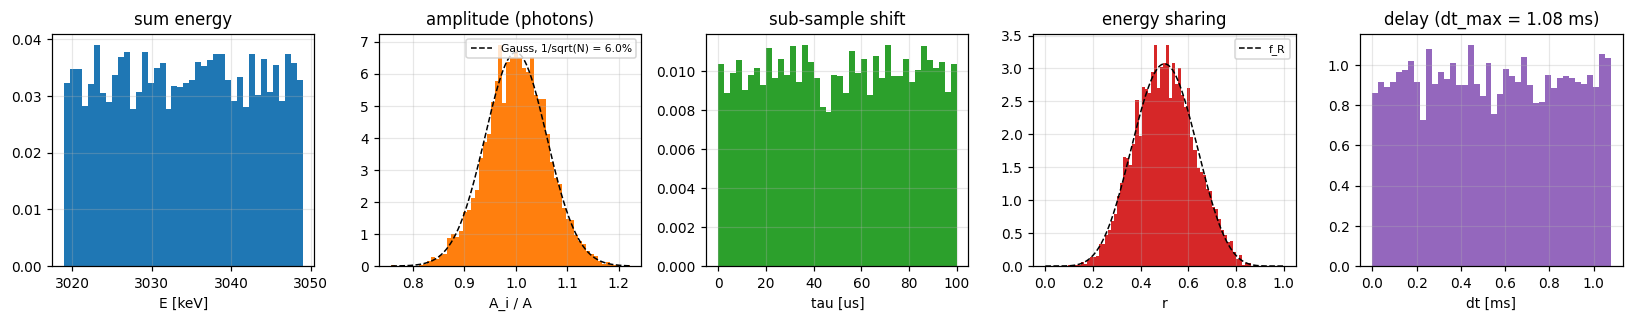

In [21]:
def generate(n_blocks, nps_scale=1.0, dt_max=DT_MAX, shift=1 / FS):
    # n_blocks blocchi da 500 eventi con gli stessi seed del Monte Carlo; restituisce (primi 5 eventi di ogni blocco, info)
    rng, rng_x = np.random.default_rng(SEED), np.random.default_rng([SEED, 1])
    pulses, infos = [], []
    for _ in range(n_blocks):
        fp, info = sim.simulate_frequency_pulses_v2(S_fit, nps * nps_scale, w, 500, rng, rng_x, signal_scale=A_ROI,
                                                    dt_max=dt_max, n_photons=N_GAMMA, e_roi=fn.E_ROI_MEV,
                                                    q_value=fn.Q_BB_MEV, shift_max=shift)
        pulses.append(np.fft.ifft(fp[:5], axis=1).real)
        info["a_hat"] = (fp @ np.conj(S_fit)).real / np.sum(np.abs(S_fit) ** 2)   # ampiezza proiettata sul template
        infos.append(info)
    return np.concatenate(pulses), {k_: np.concatenate([i[k_] for i in infos]) for k_ in infos[0]}

_, gen = generate(10)                                             # 5000 pile-up
_, clean = generate(10, nps_scale=1e-20, dt_max=0.0, shift=0.0)   # stessi eventi: singoli, senza rumore ne' shift

fig, ax = plt.subplots(1, 5, figsize=(15, 3))
ax[0].hist(gen["energy"] * 1e3, 40, density=True, color="C0"); ax[0].set(xlabel="E [keV]", title="sum energy")
x = clean["a_hat"] / A_ROI
ax[1].hist(x, 60, density=True, color="C1")
xx = np.linspace(x.min(), x.max(), 200)
ax[1].plot(xx, np.exp(-0.5 * ((xx - 1) * np.sqrt(N_GAMMA)) ** 2) * np.sqrt(N_GAMMA / (2 * np.pi)), "k--", lw=1,
           label=f"Gauss, 1/sqrt(N) = {1 / np.sqrt(N_GAMMA):.1%}")
ax[1].set(xlabel="A_i / A", title="amplitude (photons)"); ax[1].legend(fontsize=7)
ax[2].hist(gen["tau"] * 1e6, 40, density=True, color="C2"); ax[2].set(xlabel="tau [us]", title="sub-sample shift")
ax[3].hist(gen["r"], 60, density=True, color="C3")
rr = np.linspace(0, 1, 400); ax[3].plot(rr, dbs.pdf_ratio2b(rr), "k--", lw=1, label="f_R")
ax[3].set(xlabel="r", title="energy sharing"); ax[3].legend(fontsize=7)
ax[4].hist(gen["dt"] * 1e3, 40, density=True, color="C4"); ax[4].set(xlabel="dt [ms]", title=f"delay (dt_max = {DT_MAX * 1e3:.2f} ms)")
plt.tight_layout()
print(f"A_i/A: media {x.mean():.4f}, dispersione {x.std():.4f} (attesa {1 / np.sqrt(N_GAMMA):.4f})")

la media di tutta la finestra contiene l'integrale dell'impulso: +1.58e-04 V = 4.43% dell'ampiezza


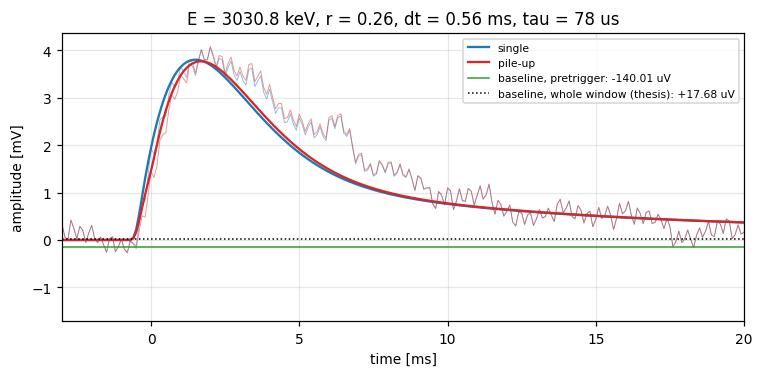

In [22]:
# un evento: lo stesso pile-up e il suo singolo, con e senza rumore (stessi numeri casuali), e le due baseline
p_noisy, info = generate(1)
p_clean, _ = generate(1, nps_scale=1e-20)
s_noisy, _ = generate(1, dt_max=0.0)
s_clean, _ = generate(1, nps_scale=1e-20, dt_max=0.0)
i = int(np.argmax(info["dt"][:5] > 0.5 * DT_MAX))              # uno dei primi 5 eventi con dt > dt_max / 2
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t_ms, s_noisy[i] * 1e3, color="C0", lw=0.6, alpha=0.5)
ax.plot(t_ms, p_noisy[i] * 1e3, color="C3", lw=0.6, alpha=0.5)
ax.plot(t_ms, s_clean[i] * 1e3, color="C0", lw=1.5, label="single")
ax.plot(t_ms, p_clean[i] * 1e3, color="C3", lw=1.5, label="pile-up")
b_pre, b_all = p_noisy[i, :4900].mean(), p_noisy[i].mean()
ax.axhline(b_pre * 1e3, color="C2", lw=1, label=f"baseline, pretrigger: {b_pre * 1e6:+.2f} uV")
ax.axhline(b_all * 1e3, color="k", ls=":", lw=1, label=f"baseline, whole window (thesis): {b_all * 1e6:+.2f} uV")
ax.set(xlim=(-3, 20), xlabel="time [ms]", ylabel="amplitude [mV]",
       title=f"E = {info['energy'][i] * 1e3:.1f} keV, r = {info['r'][i]:.2f}, dt = {info['dt'][i] * 1e3:.2f} ms, "
             f"tau = {info['tau'][i] * 1e6:.0f} us")
ax.legend(fontsize=7)
print(f"la media di tutta la finestra contiene l'integrale dell'impulso: {b_all - b_pre:+.2e} V = {(b_all - b_pre) / A_ROI:.2%} dell'ampiezza")

### Il Monte Carlo del BI
I filtri appena addestrati, applicati a 50 000 singoli e 50 000 pile-up: uno dei 50 seed della campagna.

In [23]:
filters = [(res["kernel"], res["f1"], res["f2"])]              # kernel H e filtri di banda dell'addestramento
v2 = dict(n_photons=N_GAMMA, e_roi=fn.E_ROI_MEV, shift_max=1 / FS, jitter_max=JITTER, nsim=NSIM)

t0 = time.perf_counter()
info_p = []
(y_s,) = mc.simulate_psd_v2(S_fit, nps, w, filters, A_ROI, 0.0, SEED, **v2)
(y_p,) = mc.simulate_psd_v2(S_fit, nps, w, filters, A_ROI, DT_MAX, SEED, info_out=info_p, **v2)
out = mc.bi_from(y_s, y_p, K)
dt_p = np.concatenate([d["dt"] for d in info_p])
print(f"Monte Carlo in {time.perf_counter() - t0:.0f} s")
print(f"BI_MC = {out['BI_mc']:.3e} +- {out['sigma_BI']:.1e} counts/(keV kg yr)   (rigettato r_p = {out['rp']:.4f})")
print(f"BI analitico = {res['BI']:.3e}  ->  MC / analitico = {out['BI_mc'] / res['BI']:.3f}")

Monte Carlo in 134 s
BI_MC = 9.396e-05 +- 7.9e-07 counts/(keV kg yr)   (rigettato r_p = 0.7371)
BI analitico = 9.126e-05  ->  MC / analitico = 1.030


BI con dt_max = 0.80 ms: 9.237e-05
BI con dt_max = 1.08 ms: 9.396e-05


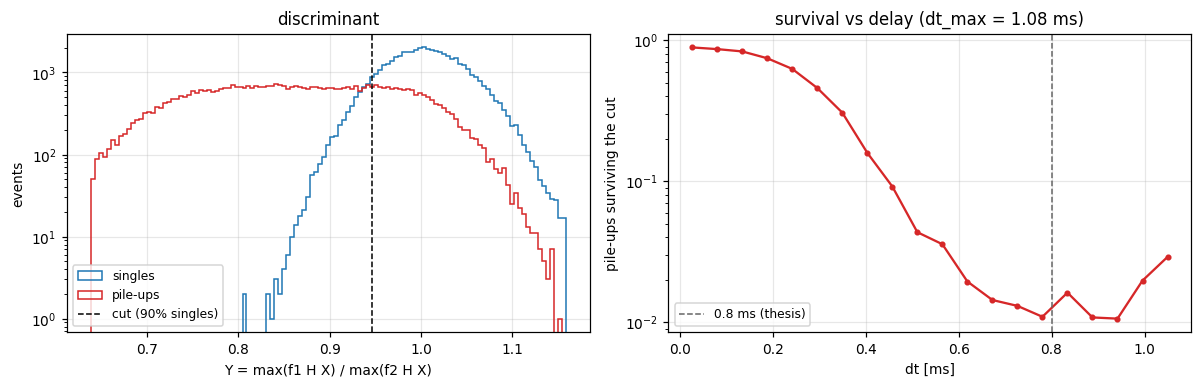

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(np.percentile(y_p, 0.5), np.percentile(y_s, 99.9), 120)
ax[0].hist(y_s, bins, histtype="step", color="C0", label="singles")
ax[0].hist(y_p, bins, histtype="step", color="C3", label="pile-ups")
ax[0].axvline(out["cut"], color="k", ls="--", lw=1, label="cut (90% singles)")
ax[0].set(xlabel="Y = max(f1 H X) / max(f2 H X)", ylabel="events", yscale="log", title="discriminant")
ax[0].legend(fontsize=8)
edges = np.linspace(0, DT_MAX, 21)
idx = np.digitize(dt_p, edges) - 1
surv = np.array([np.mean(y_p[idx == j] >= out["cut"]) for j in range(len(edges) - 1)])
ax[1].plot(0.5 * (edges[1:] + edges[:-1]) * 1e3, surv, "o-", ms=3, color="C3")
if DT_MAX > 0.8e-3:
    ax[1].axvline(0.8, color="0.4", ls="--", lw=1, label="0.8 ms (thesis)")
    ax[1].legend(fontsize=8)
ax[1].set(xlabel="dt [ms]", ylabel="pile-ups surviving the cut", yscale="log", title=f"survival vs delay (dt_max = {DT_MAX * 1e3:.2f} ms)")
plt.tight_layout()
# il BI con una finestra piu' corta si legge dagli stessi eventi: dt e' uniforme, quindi BI(d) = K(d) * sopravvivenza(dt < d)
for d in sorted({min(0.8e-3, DT_MAX), DT_MAX}):
    print(f"BI con dt_max = {d * 1e3:.2f} ms: {fn.K_for(d) * np.mean(y_p[dt_p < d] >= out['cut']):.3e}")

**Come si legge la sopravvivenza in funzione del ritardo.** Sotto qualche decimo di ms i due impulsi sono
indistinguibili e quasi tutti i pile-up passano il taglio; poi la reiezione migliora rapidamente. Il BI con una finestra
più corta si legge dagli stessi eventi, perché il ritardo è uniforme. Con 40 passi di addestramento i filtri non sono
ancora convergiti: i numeri di questo punto sono un'illustrazione, non un risultato.

### Quanto pesa ogni novità del Monte Carlo (confronto appaiato)
Stessi filtri e stessi seed, quindi stessi rumore, $r$ e $\Delta t$: si accendono le novità una alla volta, partendo
dalla generazione della tesi con il nuovo $\Delta t_{\max}$ e le ampiezze della sezione 1. Le differenze sono appaiate e
quindi molto più precise del BI di ciascuna riga; con un solo seed però non hanno una barra d'errore, per quella serve
la campagna (50 seed, `compare_templates_m205.py`).

In [25]:
variants = {"generazione e baseline della tesi": dict(n_photons=None, e_roi=None, shift_max=0.0, pre_baseline=False),
            "+ baseline sul pretrigger": dict(n_photons=None, e_roi=None, shift_max=0.0),
            "+ fotoni": dict(n_photons=N_GAMMA, e_roi=None, shift_max=0.0),
            "+ energia nella ROI": dict(n_photons=N_GAMMA, e_roi=fn.E_ROI_MEV, shift_max=0.0)}
bi = {}
t0 = time.perf_counter()
for name, kw in variants.items():
    kw = dict(kw, jitter_max=JITTER, nsim=NSIM)
    (s,) = mc.simulate_psd_v2(S_fit, nps, w, filters, A_ROI, 0.0, SEED, **kw)
    (p,) = mc.simulate_psd_v2(S_fit, nps, w, filters, A_ROI, DT_MAX, SEED, **kw)
    bi[name] = mc.bi_from(s, p, K)["BI_mc"]
bi["+ shift sub-campione (tutto acceso)"] = out["BI_mc"]
print(f"({time.perf_counter() - t0:.0f} s)\n")
prev = None
for name, v in bi.items():
    print(f"{name:<38s} BI_MC = {v:.4e}" + ("" if prev is None else f"   {100 * (v / prev - 1):+6.2f}% sul precedente"))
    prev = v

(437 s)

generazione e baseline della tesi      BI_MC = 9.3533e-05
+ baseline sul pretrigger              BI_MC = 9.3647e-05    +0.12% sul precedente
+ fotoni                               BI_MC = 9.4047e-05    +0.43% sul precedente
+ energia nella ROI                    BI_MC = 9.4083e-05    +0.04% sul precedente
+ shift sub-campione (tutto acceso)    BI_MC = 9.3961e-05    -0.13% sul precedente


In [26]:
print(f"ch{CH} WP{WP}, V_bias {VBIAS} V")
print(f"  A_LED = {A_LED * 1e3:.1f} mV -> A_ROI = {A_ROI * 1e3:.3f} mV;  N_gamma = {N_GAMMA:.0f};  SNR_OF = {A_ROI / sigma_OF:.1f}")
print(f"  dt_max = rise time = {DT_MAX * 1e3:.3f} ms;  K = {K:.3e}")
print(f"  BI analitico = {res['BI']:.3e};  BI_MC = {out['BI_mc']:.3e} +- {out['sigma_BI']:.1e};  MC / analitico = {out['BI_mc'] / res['BI']:.3f}")

ch31 WP7, V_bias 1.8 V
  A_LED = 743.0 mV -> A_ROI = 3.556 mV;  N_gamma = 279;  SNR_OF = 20.0
  dt_max = rise time = 1.076 ms;  K = 3.573e-04
  BI analitico = 9.126e-05;  BI_MC = 9.396e-05 +- 7.9e-07;  MC / analitico = 1.030


## 7. La campagna sul server

Il notebook usa le stesse funzioni dei programmi della campagna. Per i 75 punti:

1. **Template** — `build_simAP_injected_m205.py` con `MODE = "mc_v2"` (gira anche in locale, circa 12 s a punto):
   scrive `m205_AP_sim/ch<ch>/simAP_APsimfit10000ledv2_ch<ch>_wp<wp>.npy`.
2. **Addestramento** — `analyse_BI_m205.py` e `analysis_BI_m205_wiener_regolarized.py`, già impostati con
   `TEMPLATE_SOURCE = "sim"`, `SIM_SOURCE = "APsimfit10000ledv2"`, `T_MAX = "rise"`. Le cartelle prendono il suffisso
   `_dtrise`, per esempio `m205_results_octopus_APsimfit10000ledv2_npsclean_dtrise`, e non si mescolano con quelle della
   tesi.
3. **Monte Carlo** — `simulate_BI_error_m205.py` con `GEN_V2 = True`, `T_MAX = "rise"`, `RESULTS_NAME`/`COMPARE` = le
   nuove cartelle, `N_SEEDS = 50`: scrive `BI_mc_error_m205_v2_seeds50.csv`. Se `T_MAX` non coincide con il suffisso
   della cartella, il programma si ferma.
4. **Confronti** — `compare_templates_m205.py` con `SETS` = le nuove cartelle e `MC_CSV = "BI_mc_error_m205_v2_seeds50.csv"`.

**Da tenere presente**
- I **LY** di Denys hanno errori del 25–50% (tabella della sez. 1.3); un errore di un fattore $k$ sul LY cambia
  $\sigma_A/A$ di $\sqrt{k}$.
- **Energia del fotone**: 1.85 eV (670 nm). Con i 2.30 eV del codice del paper i fotoni sarebbero il 20% in meno, con
  i 2.1 eV di Armatol 2026 il 12% in meno.
- La **proiezione alle condizioni di CUPID** (light yield e guadagno NTL della baseline di CUPID) è rimandata; quello
  che si è raccolto finora è in `tesi_note/riscalamento_CUPID.md`.
- **Forma degli impulsi**: template e rise time vengono dagli impulsi LED. Va verificato che la luce di scintillazione
  del LMO dia la stessa forma, confrontando l'impulso medio dei light detector in coincidenza con la riga a 2615 keV
  (m204) con quello dei LED.
- La fluttuazione dei fotoni è un fattore comune all'evento, come nel codice del paper: i due impulsi di un pile-up
  fluttuano insieme.